In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *
from class_utils import *

import Orange
from orangecontrib.spectroscopy import data
from Orange.data.io import FileFormat

In [2]:
df_library = pd.read_csv('spectral_data_all.csv')
df_library.drop(columns=['Unnamed: 0'], inplace=True)
df_flopp = df_library.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_flopp = df_flopp.query('intensity > 0')
df_flopp = norm_spect(df_flopp, norm_type='SNV')
df_flopp_pivot = df_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[3:]
#df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


#X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)

X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
#y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)

y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'

x_train = x_train[:,idx_range]
x_test = X_test.iloc[:,idx_range]

n, p = x_train.shape

NameError: name 'idx_range' is not defined

In [ ]:
print(y_train[0])
plt.plot(x_train[0,:])

In [ ]:
clf = model_logReg(C=7)
clf.train_data(-x_train, y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
#y_test_hat = clf.predict(X_test)
clf.score(-x_test, y_test)

In [ ]:
spectra_df_long

In [ ]:
spectra_data = Orange.data.Table('OPTIR/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run1.ptir')
spectra_df = (
    spectra_data.
    X_df.T.
    reset_index().
    astype('float32'))
spectra_df.columns = ['wavelength'] + ['particle'+str(i) for i in range(spectra_df.shape[1]-1)]


spectra_df = spectra_df.astype('float32').set_index('wavelength')
spectra_df = ((spectra_df - spectra_df.mean()) / spectra_df.std()).reset_index()
spectra_df_long = spectra_df.melt(id_vars='wavelength')
spectra_df_long.columns = ['wavelength','file_name','intensity']
spectra_df_long['polymer'] = ''
spectra_df_long_int = interpol_spect(spectra_df_long, min_wl=674.9918, max_wl=3999.809,n=1725)

spectra_df_long_int_pivot = spectra_df_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

spectra_2_data = Orange.data.Table('OPTIR/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run2.ptir')
spectra_2_df = (
    spectra_2_data.
    X_df.T.
    reset_index().
    astype('float32'))
spectra_2_df.columns = ['wavelength'] + ['particle'+str(i) for i in range(spectra_2_df.shape[1]-1)]

spectra_2_df = spectra_2_df.astype('float32').set_index('wavelength')
spectra_2_df = ((spectra_2_df - spectra_2_df.mean()) / spectra_2_df.std()).reset_index()
spectra_2_df_long = spectra_2_df.melt(id_vars='wavelength')
spectra_2_df_long.columns = ['wavelength','file_name','intensity']
spectra_2_df_long['polymer'] = ''
spectra_2_df_long_int = interpol_spect(spectra_2_df_long, min_wl=674.9918, max_wl=3999.809,n=1725)

spectra_2_df_long_int_pivot = spectra_2_df_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [ ]:
spectra_data.to_pandas_dfs()[2]

In [ ]:
spectra_data.to_pandas_dfs()[2]

In [ ]:
spectra_df_long_int_pivot

In [4]:
spectra_data = Orange.data.Table('OPTIR/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run1.ptir')

In [5]:
from PIL import Image
import cv2

In [23]:
image = cv2.imread('OPTIR/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run1.png') 
image1 = cv2.imread('OPTIR/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run1_1.png') 

In [8]:
image.shape

(531, 669, 3)

In [9]:
531

531

In [66]:
beta1 = 

In [10]:
(383.099609375-11044.599609375)

-10661.5

In [12]:
coordinates = spectra_data.to_pandas_dfs()[2]#['map_x']

In [25]:
coordinates['map_y'].max(),coordinates['map_y'].min()

(-10661.5, -11044.599609375)

In [21]:
coordinates['map_x'].min()# - coordinates['map_x'].min()

27391.05078125

In [70]:
(10562.42 - coordinates['map_y'])

_o852    21251.120195
_o853    21241.769609
_o854    21233.570391
_o855    21228.769609
_o856    21251.219805
             ...     
_o927    21310.320391
_o928    21294.269609
_o929    21305.620195
_o930    21307.120195
_o931    21308.219805
Name: map_y, Length: 80, dtype: object

In [73]:
(10562.42 + coordinates['map_y'])

_o852   -126.280195
_o853   -116.929609
_o854   -108.730391
_o855   -103.929609
_o856   -126.379805
            ...    
_o927   -185.480391
_o928   -169.429609
_o929   -180.780195
_o930   -182.280195
_o931   -183.379805
Name: map_y, Length: 80, dtype: object

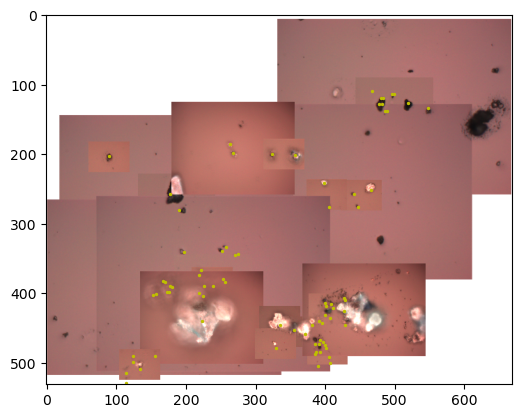

In [24]:
plt.imshow(image)

alpha = 669/(27931.34 - 27307.41)
a = 0#115

beta = 531/(11047.23 - 10562.42)
b = 0#110
plt.scatter(
    alpha*(coordinates['map_x']-27307.41) +a, 
    beta*(-10562.42 - coordinates['map_y'])+b, 
    c='y', s=2)

In [325]:
max(spectra_data.to_pandas_dfs()[2]['map_y']+11044.599609375)

383.099609375

In [339]:
spectra_data.to_pandas_dfs()[2]

,map_x,map_y
_o2932,27762.800781,-10688.700195
_o2933,27756.400391,-10679.349609
_o2934,27757.400391,-10671.150391
_o2935,27773.349609,-10666.349609
_o2936,27760.050781,-10688.799805
...,...,...
_o3007,27391.050781,-10747.900391
_o3008,27553.25,-10731.849609
_o3009,27557.550781,-10743.200195
_o3010,27609.849609,-10744.700195


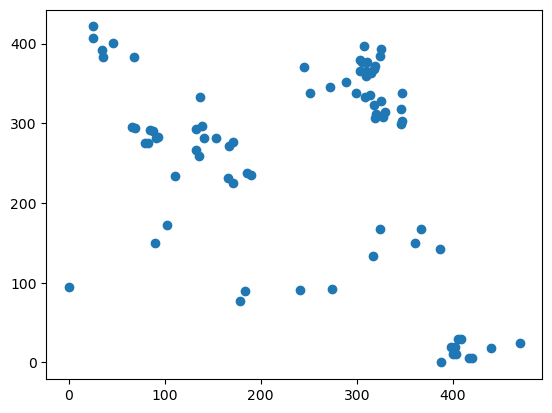

In [331]:
alpha = 1.1
beta = 1.1
plt.scatter(alpha*(spectra_data.to_pandas_dfs()[2]['map_x']-27391.05078125), 
beta*((383.099609375-11044.599609375) - spectra_data.to_pandas_dfs()[2]['map_y']))

In [5]:
idx_range = np.logical_or(
    np.logical_and(
        wl_list > (spectra_df['wavelength']).min(),
        wl_list < (spectra_df['wavelength'].to_numpy()[np.where(np.isnan(spectra_df['particle0']))]).min()-1,
    ),
    np.logical_and(
        wl_list > (spectra_df['wavelength'].to_numpy()[np.where(np.isnan(spectra_df['particle0']))]).max()+1,
        wl_list < (spectra_df['wavelength']).max(),
    )
)
idx_range

array([False, False, False, ..., False, False, False])

In [222]:
pred_probs_1 = clf.model.predict_proba(spectra_df_long_int_pivot.iloc[:,1:].iloc[:,idx_range]).max(1)
pred_probs_2 = clf.model.predict_proba(spectra_2_df_long_int_pivot.iloc[:,1:].iloc[:,idx_range]).max(1)

In [223]:
pred_polymers_1 = clf.model.predict(spectra_df_long_int_pivot.iloc[:,1:].iloc[:,idx_range])
pred_polymers_2 = clf.model.predict(spectra_2_df_long_int_pivot.iloc[:,1:].iloc[:,idx_range])

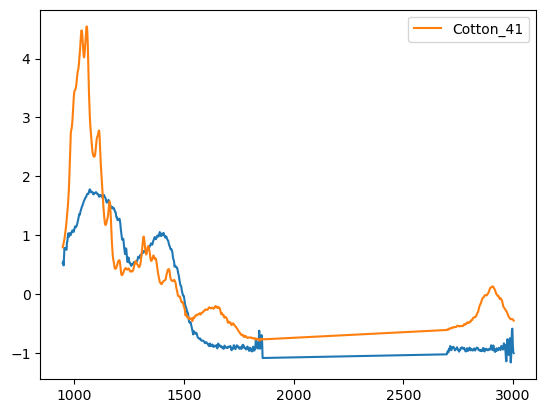

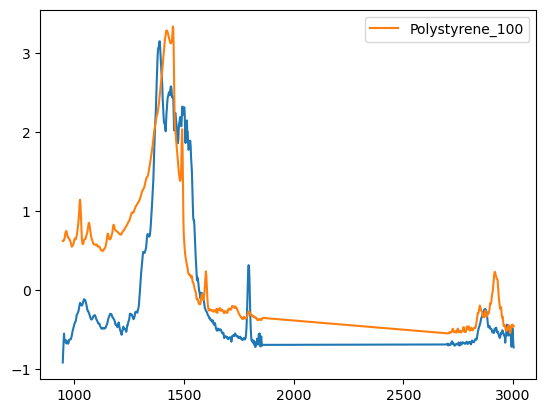

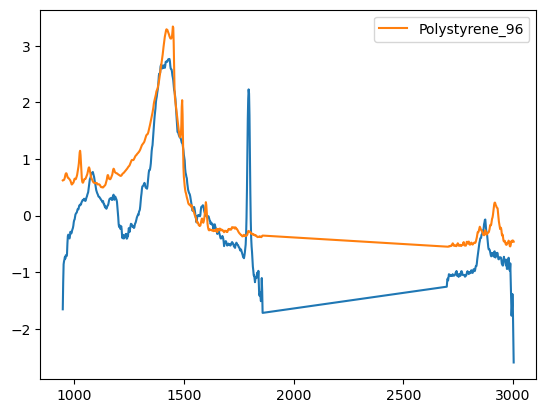

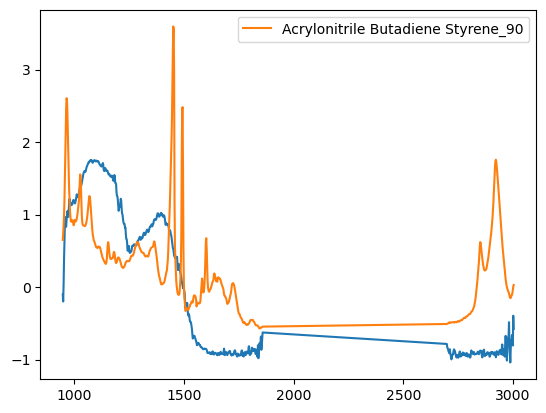

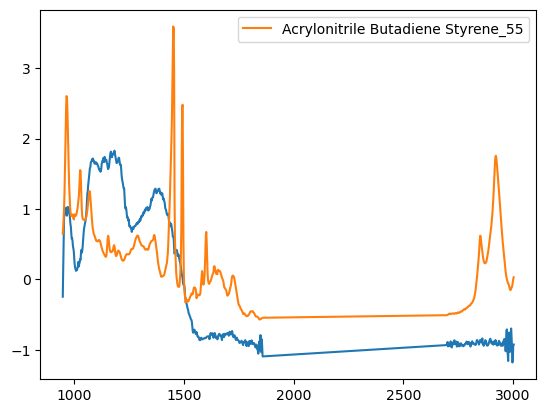

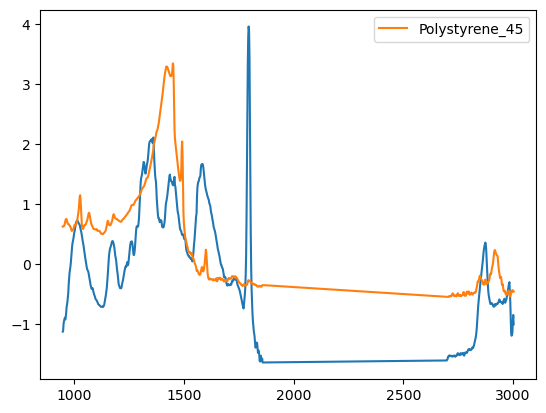

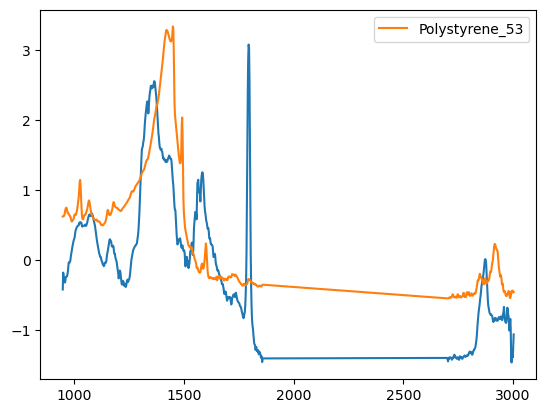

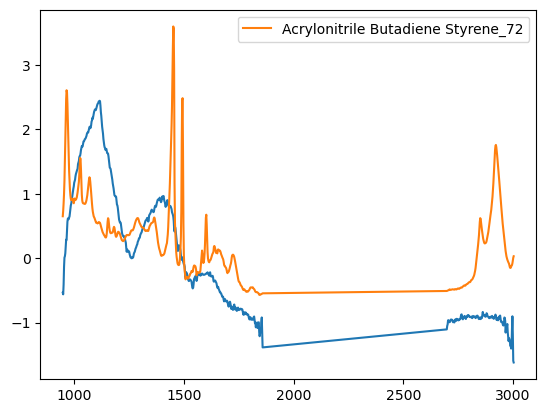

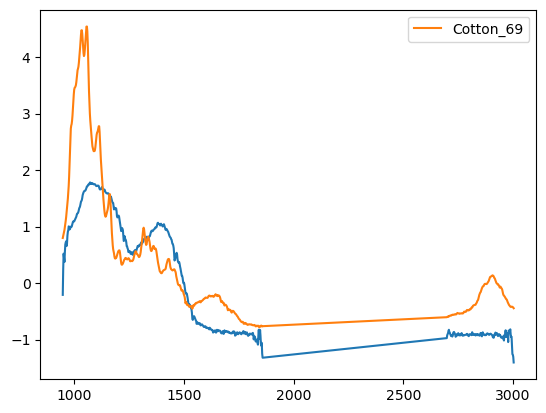

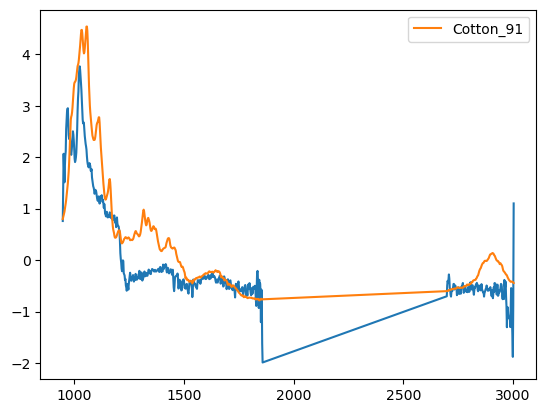

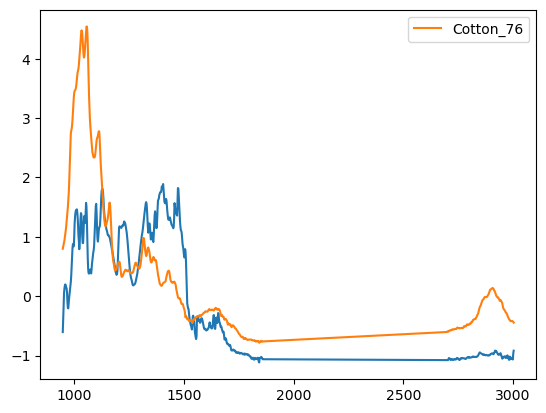

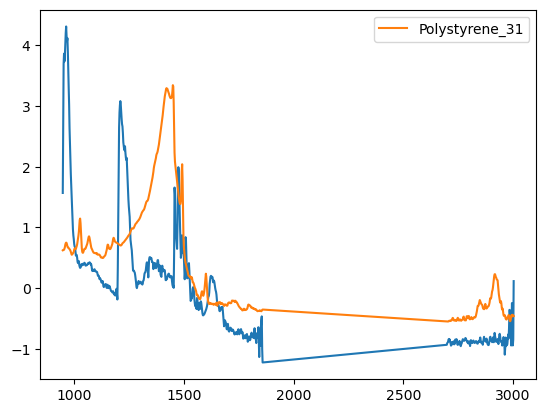

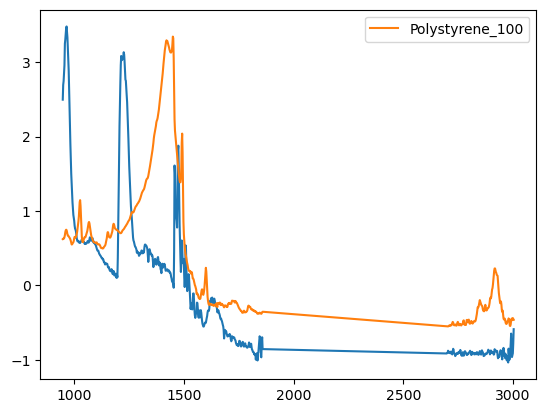

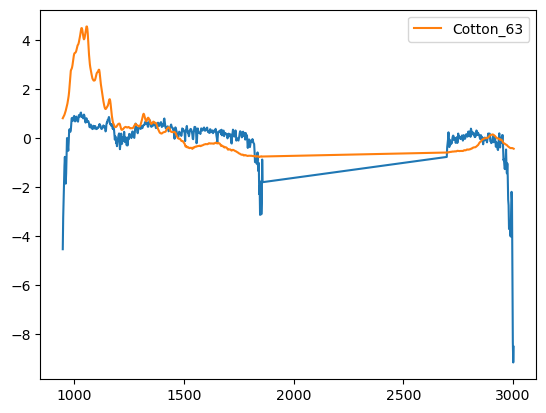

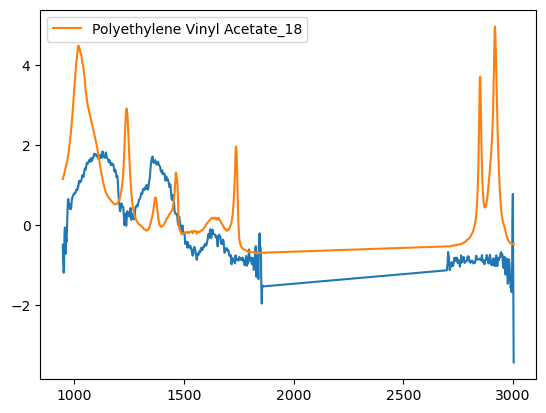

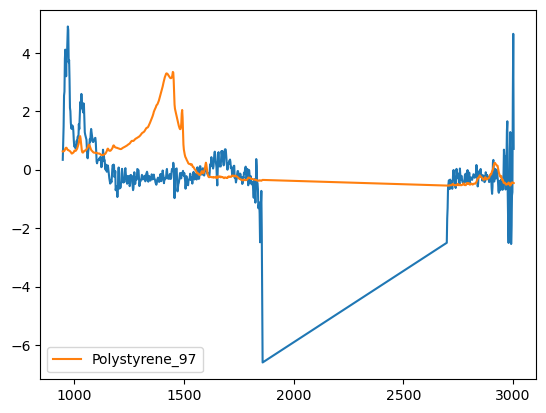

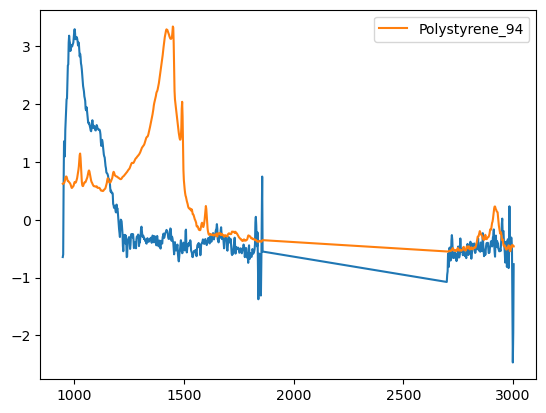

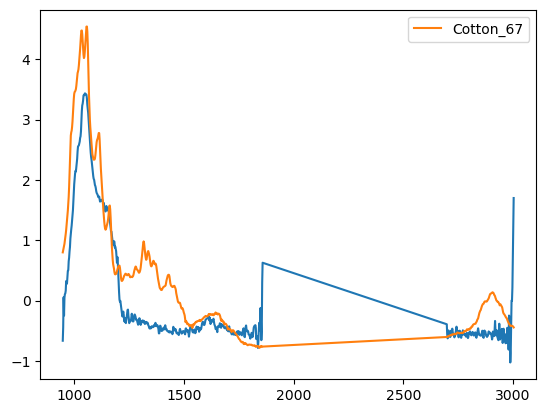

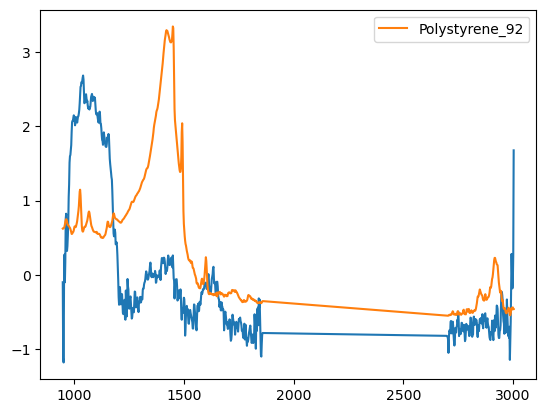

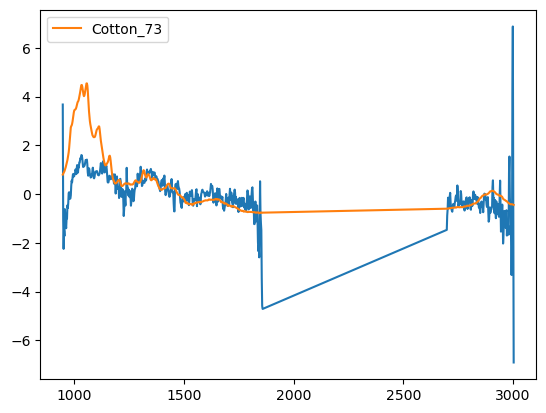

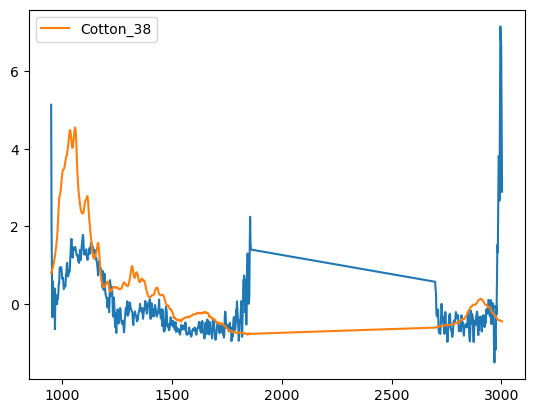

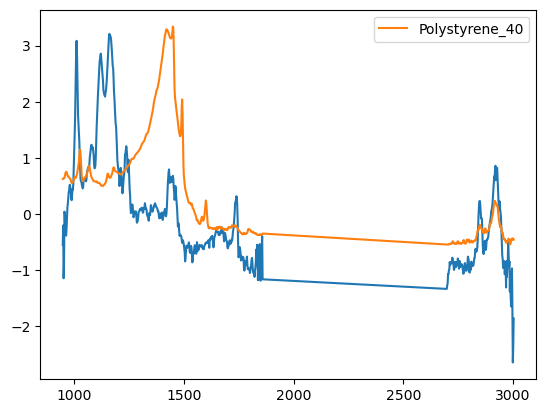

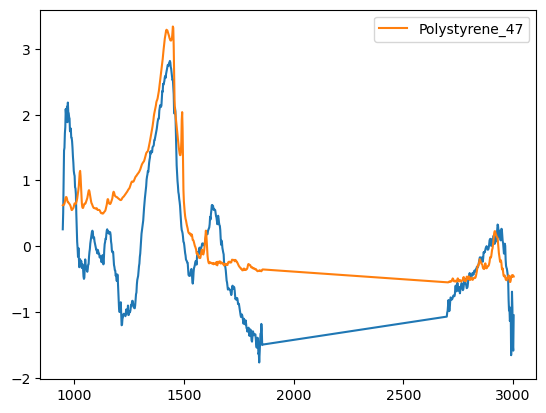

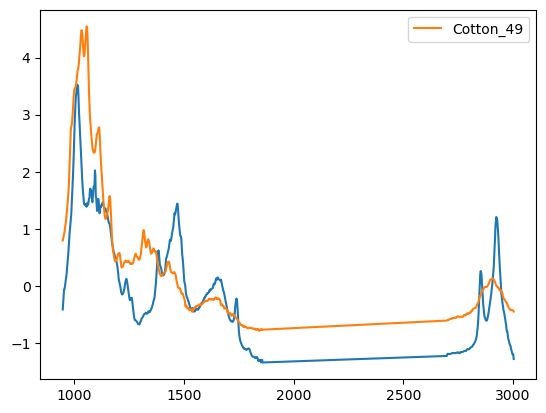

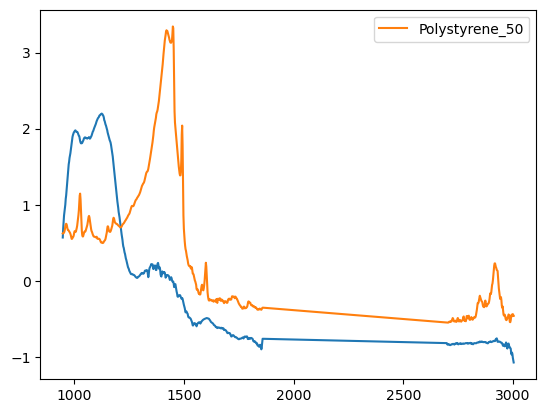

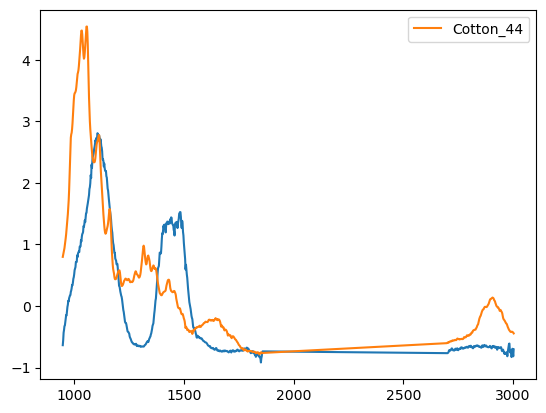

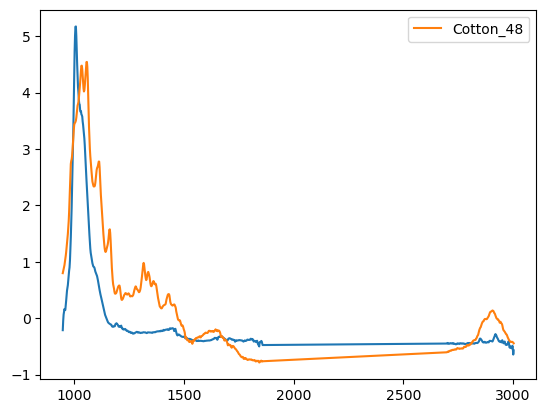

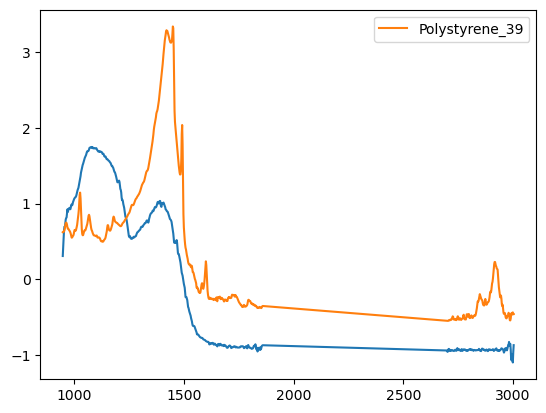

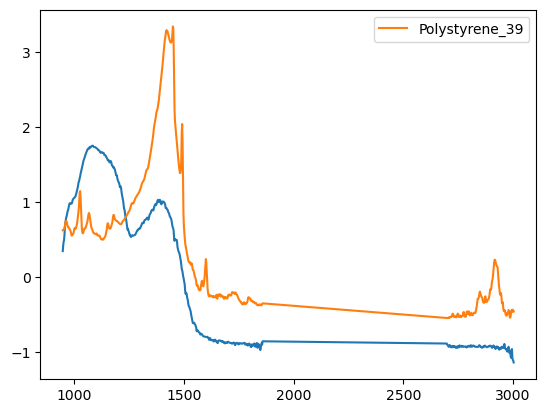

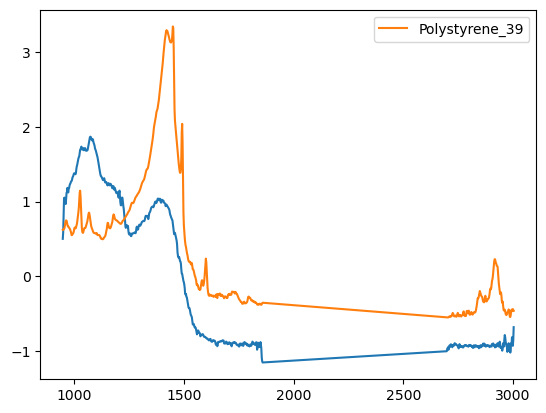

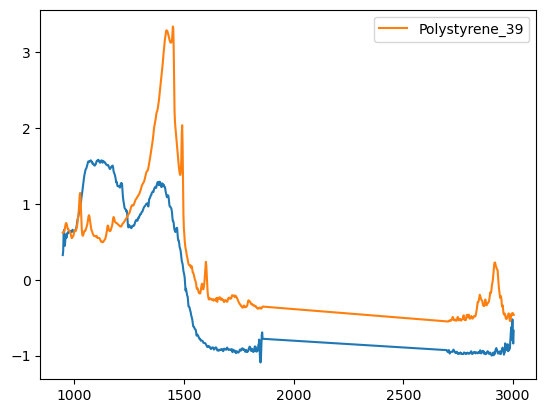

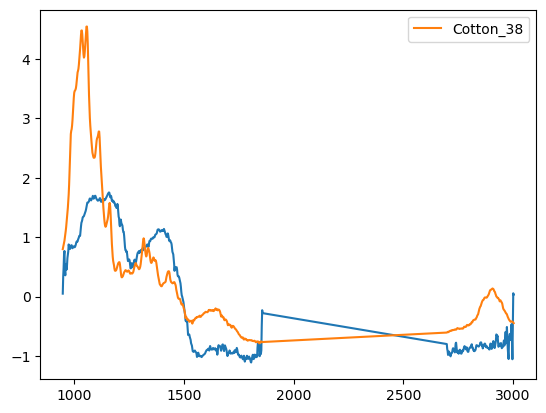

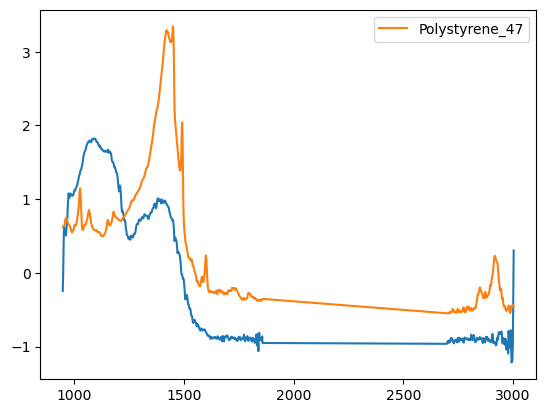

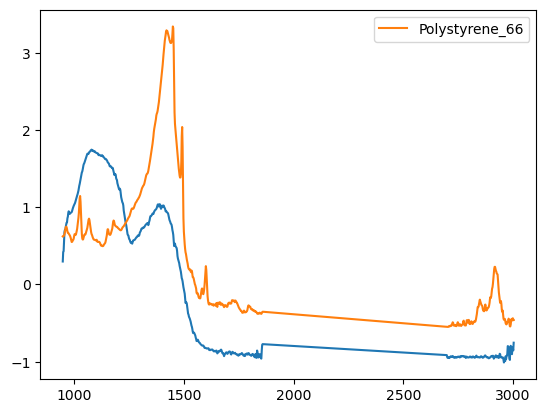

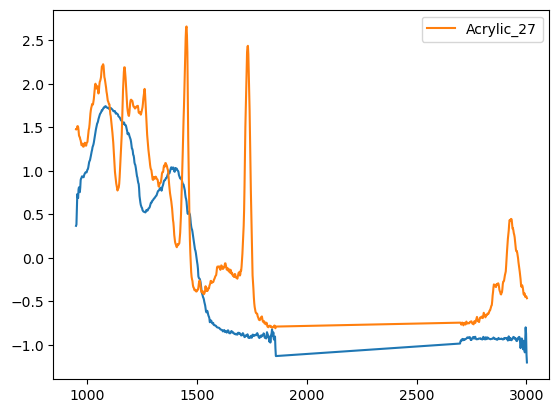

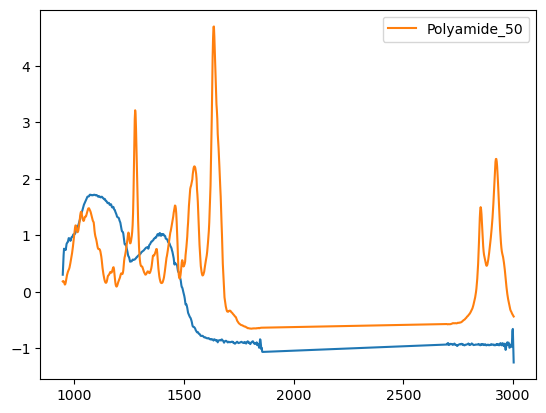

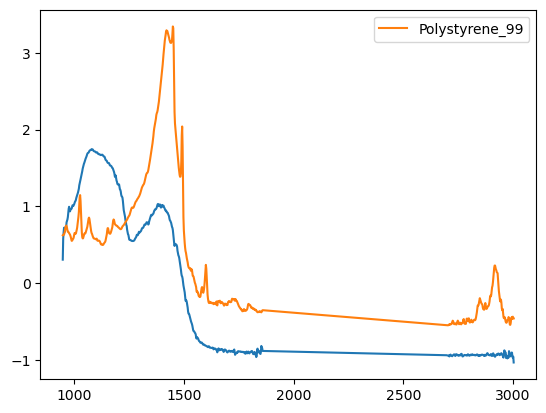

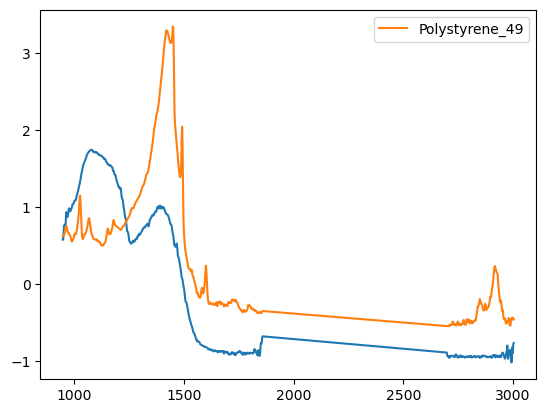

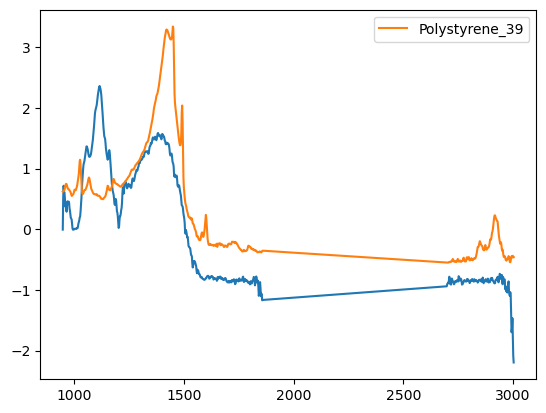

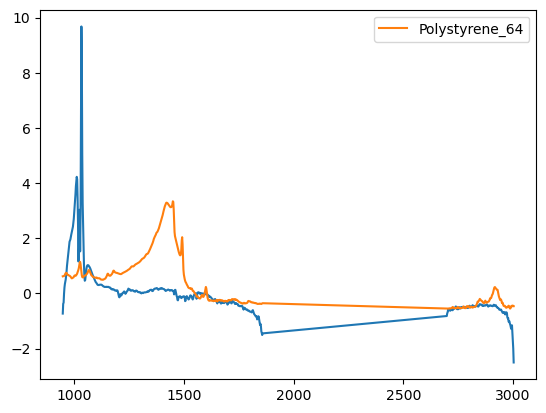

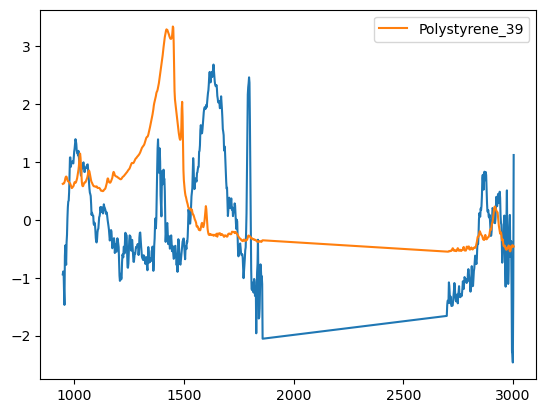

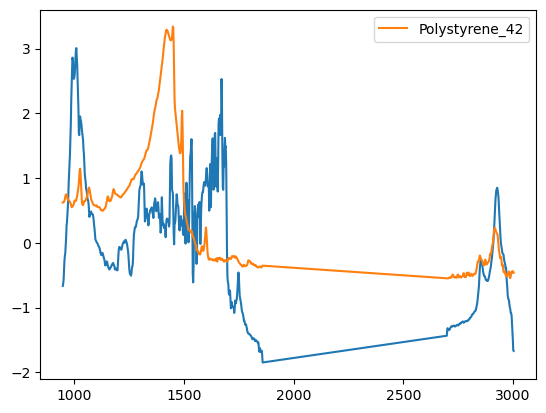

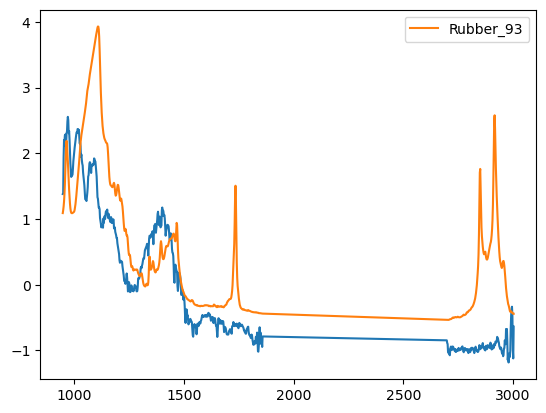

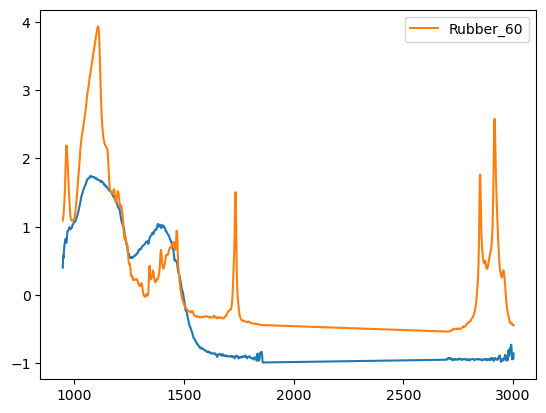

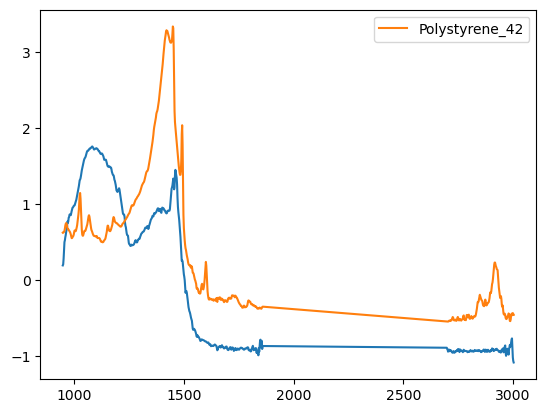

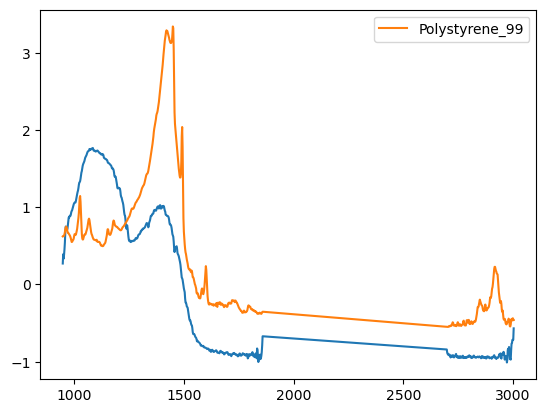

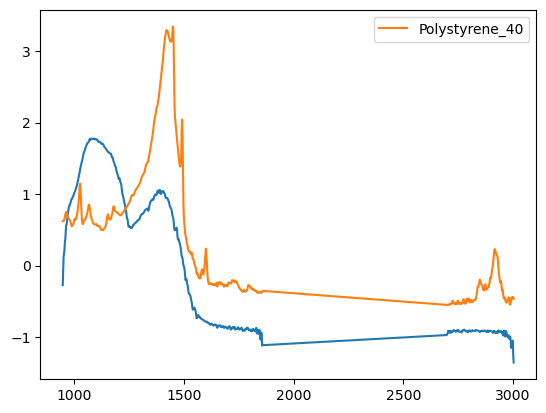

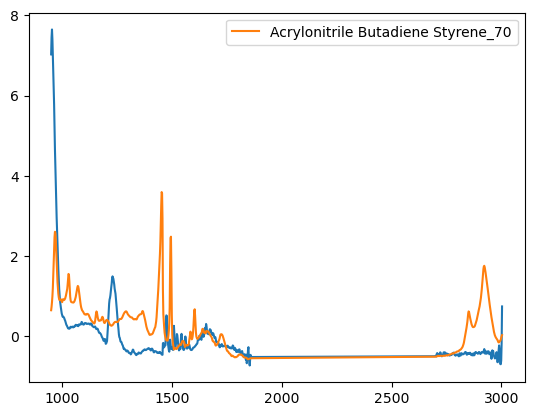

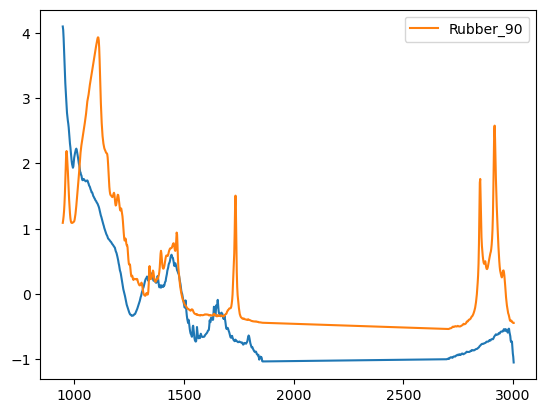

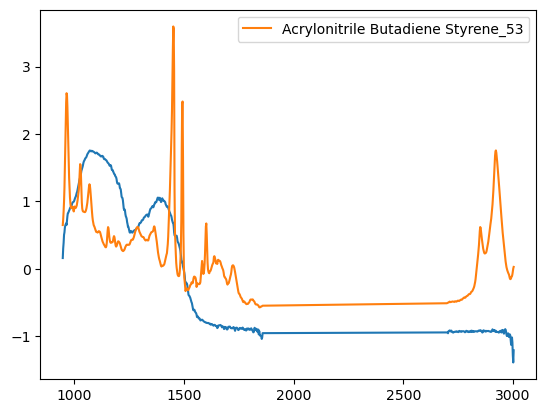

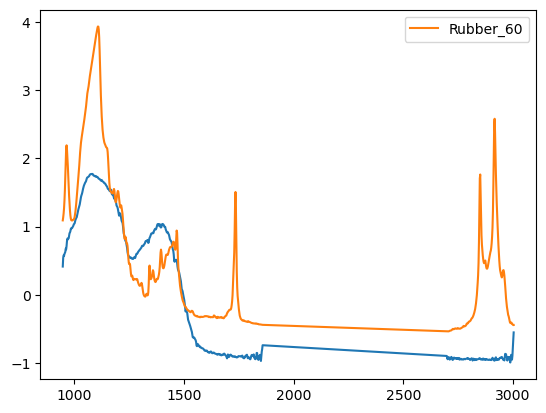

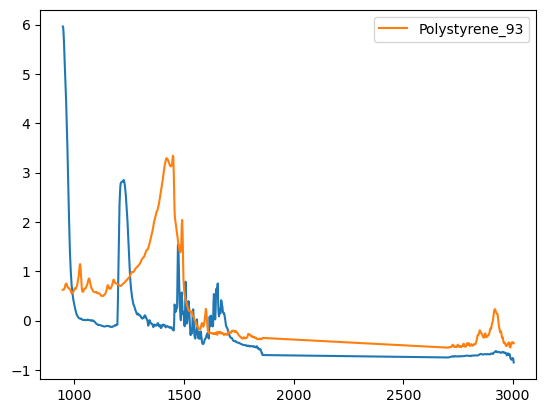

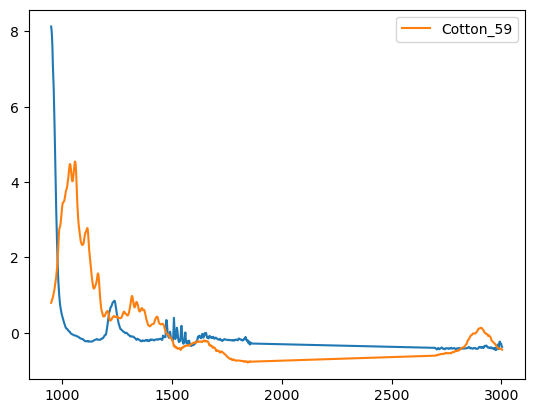

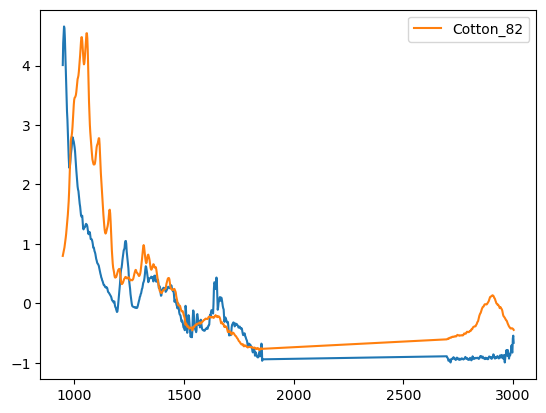

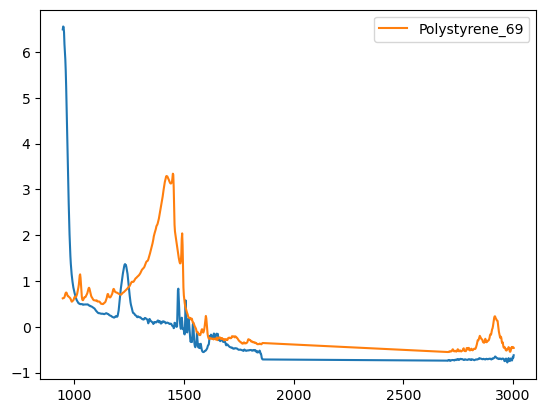

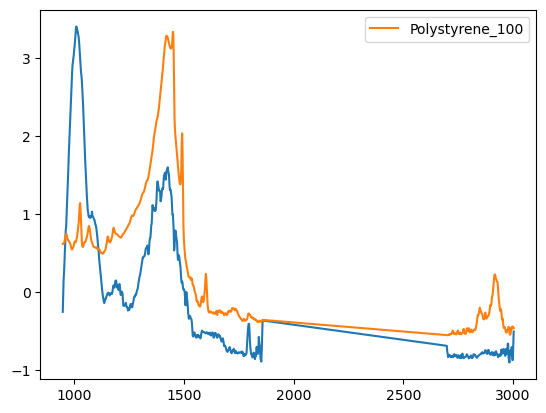

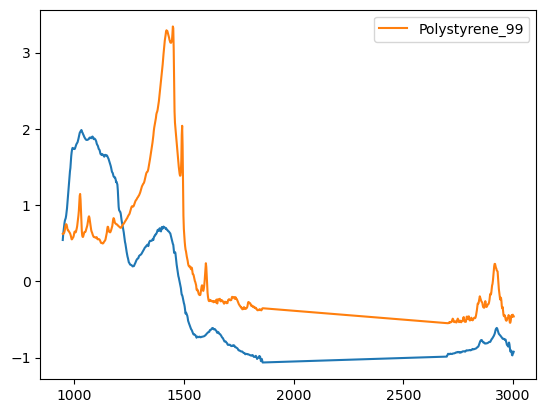

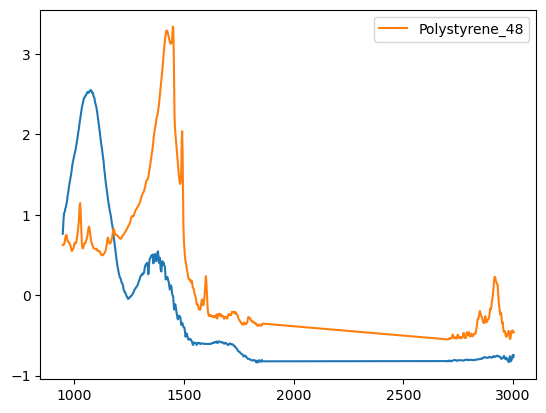

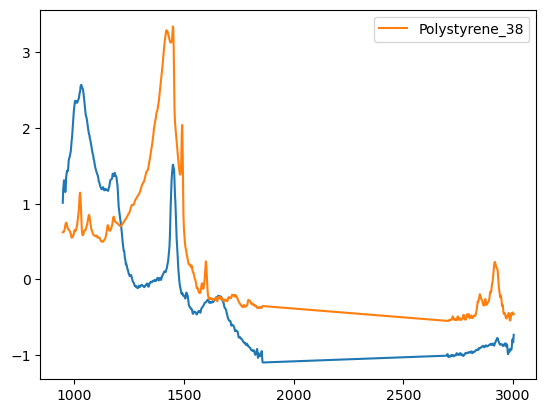

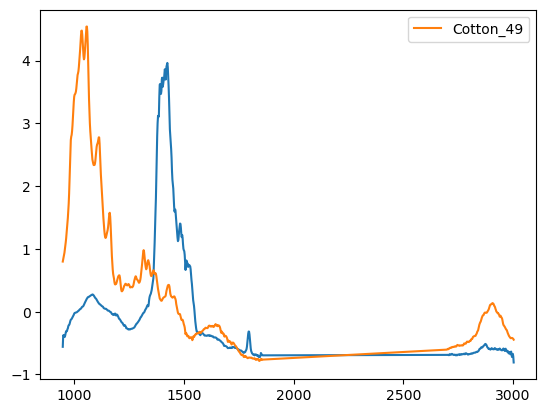

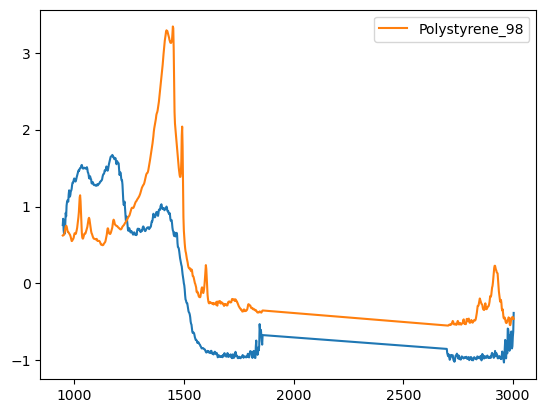

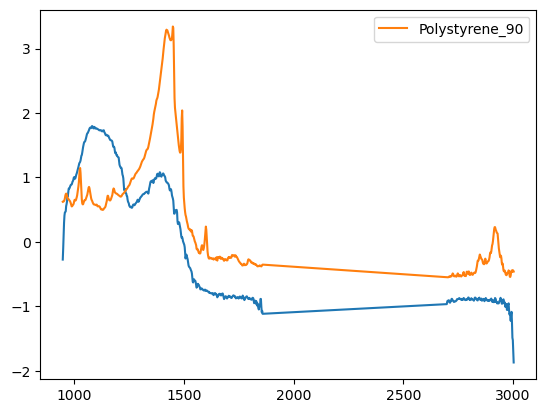

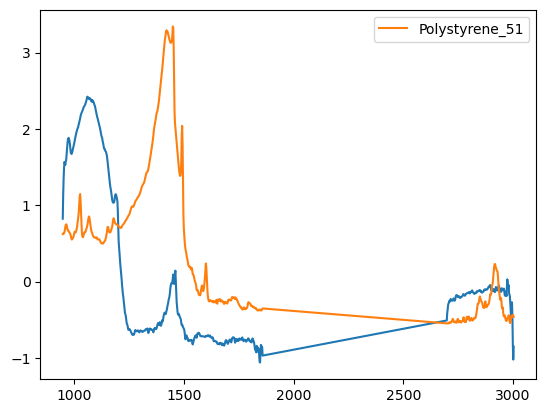

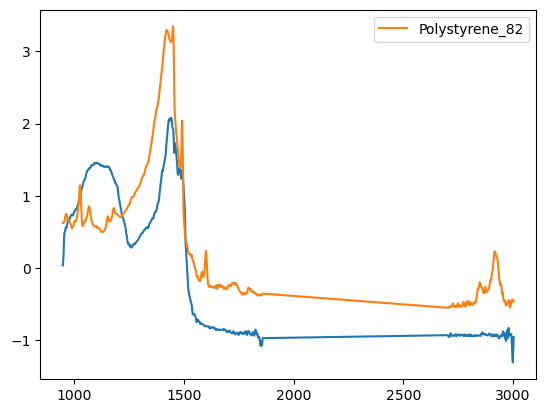

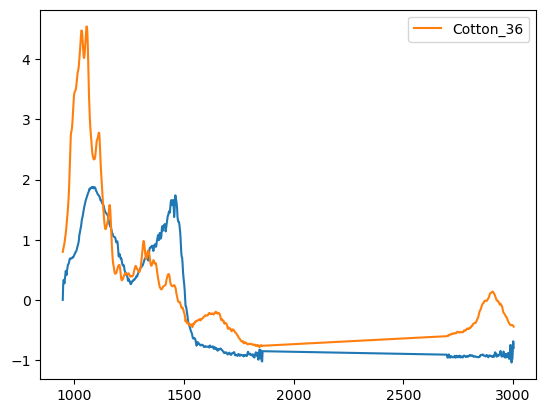

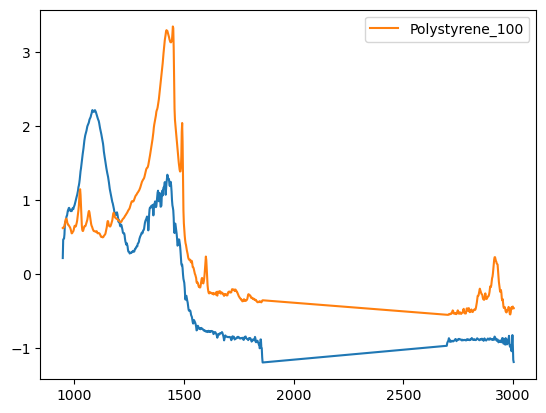

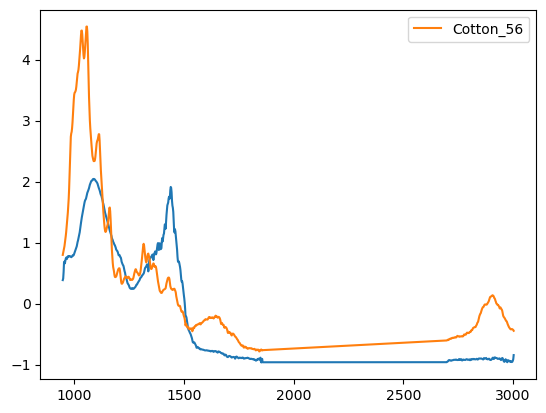

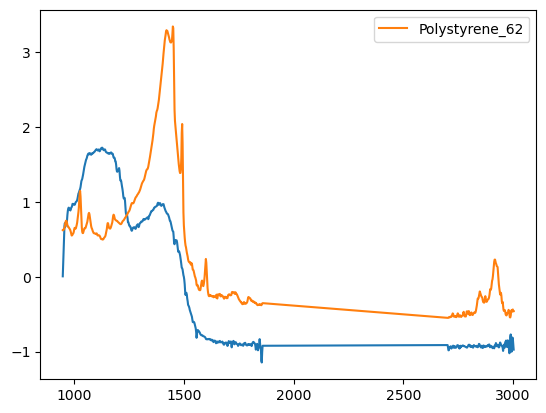

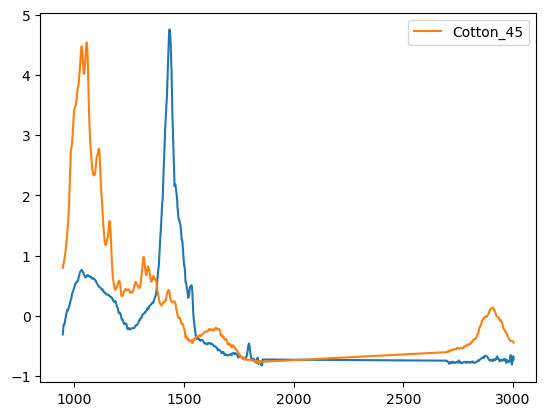

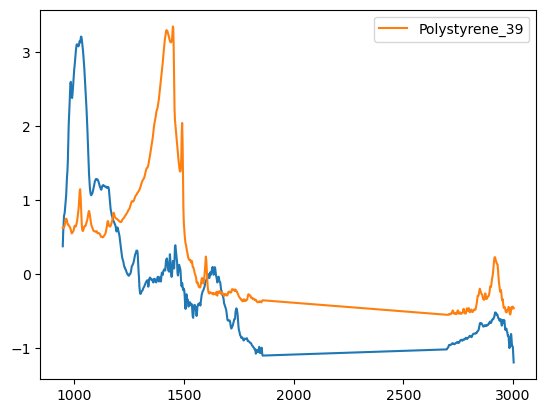

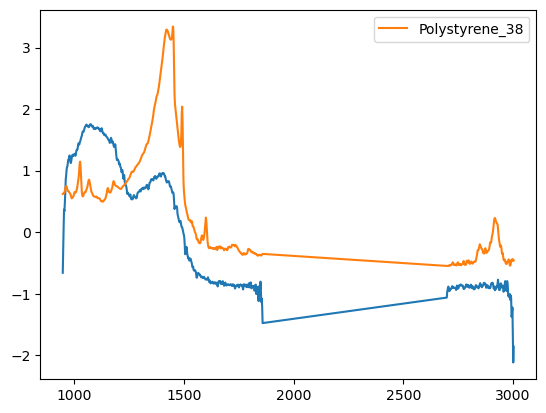

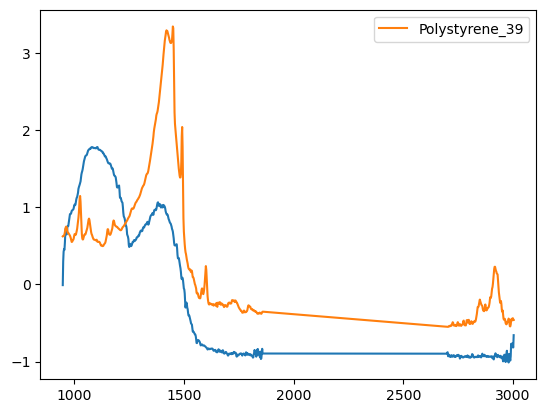

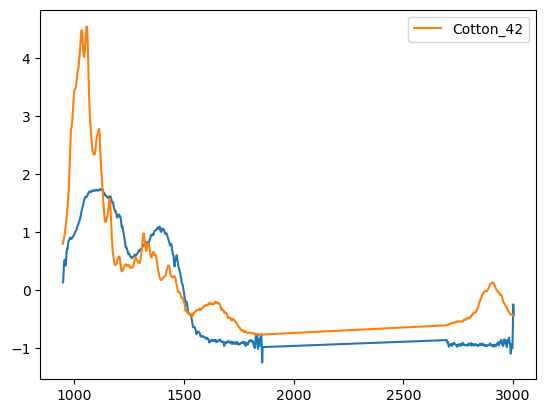

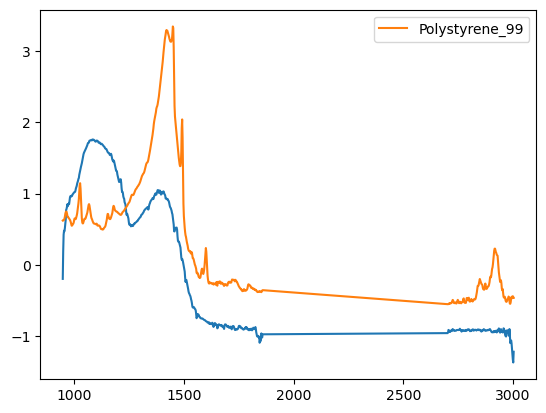

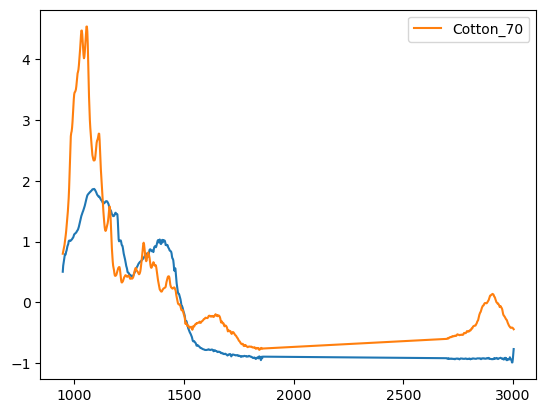

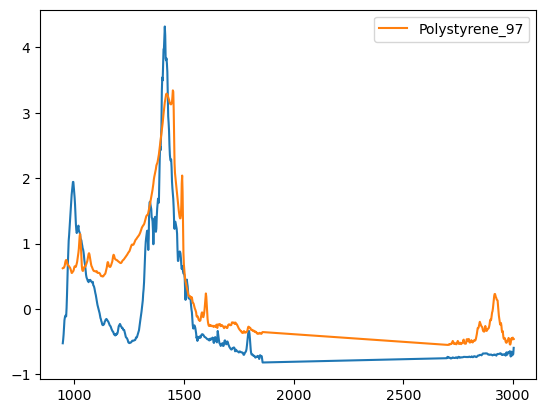

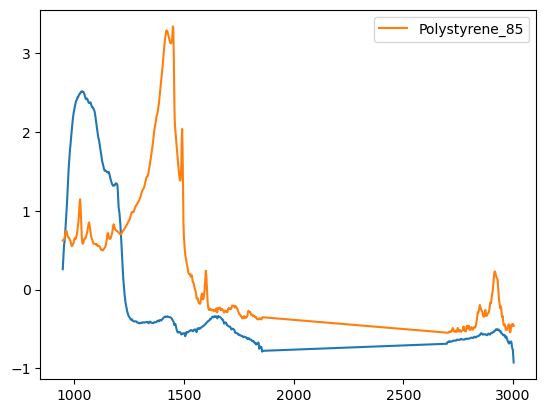

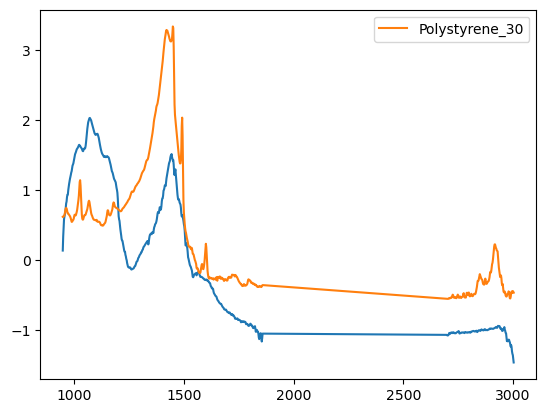

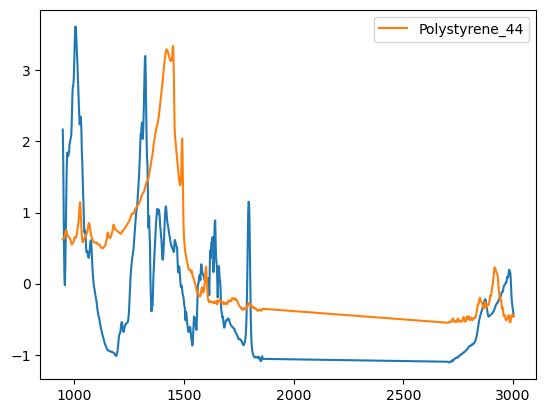

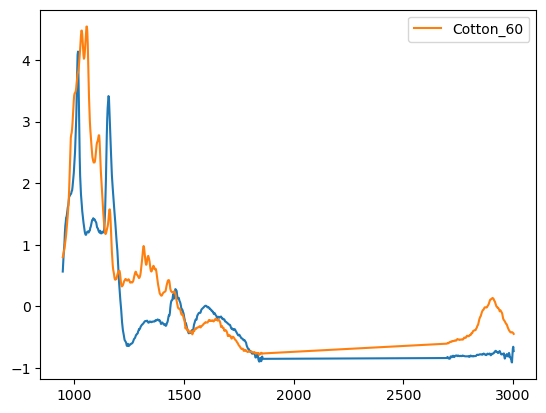

In [284]:
for i in range(80):
    if pred_probs[i] < 0.1:
        continue
    x = "particle"+str(i)
    polymer = pred_polymers[i]
    plt.plot(
        spectra_df_long_int.query('file_name == "particle0"').loc[idx_range,'wavelength'].reset_index(drop=True),
        spectra_df_long_int.query('file_name == @x').loc[idx_range,'intensity'].reset_index(drop=True)
    )
    
    plt.plot(-df_flopp_pivot.query('polymer==@polymer').iloc[0,3:][idx_range], label=polymer + '_' + str(round(100*pred_probs[i])))
    plt.legend()
    plt.show()
    
#plt.plot(-df_flopp_pivot.query('polymer=="Rubber"').iloc[0,3:][idx_range])

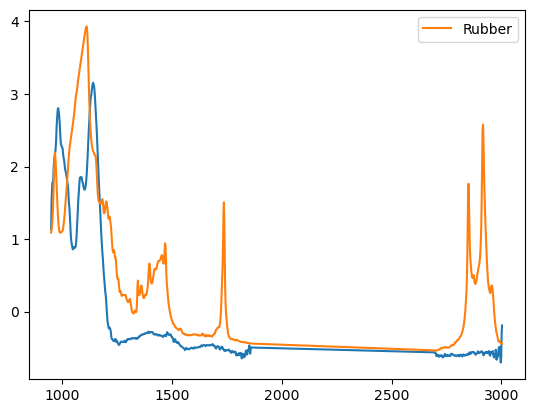

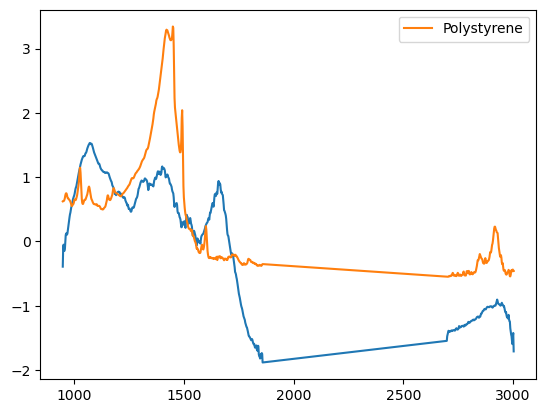

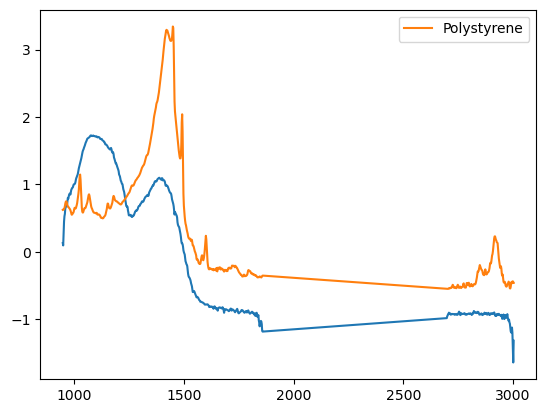

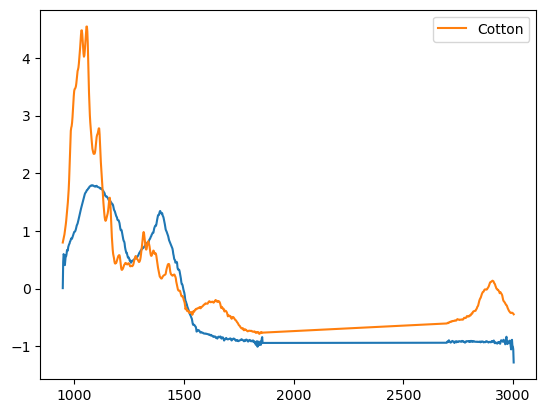

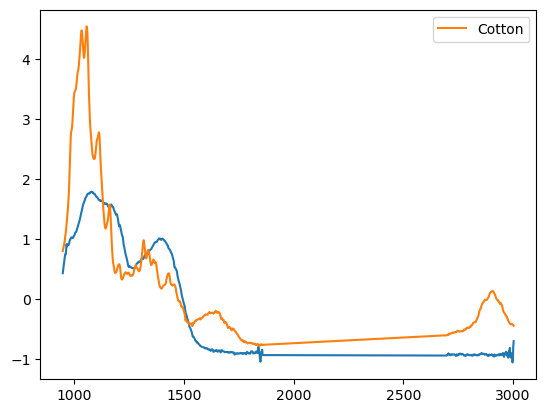

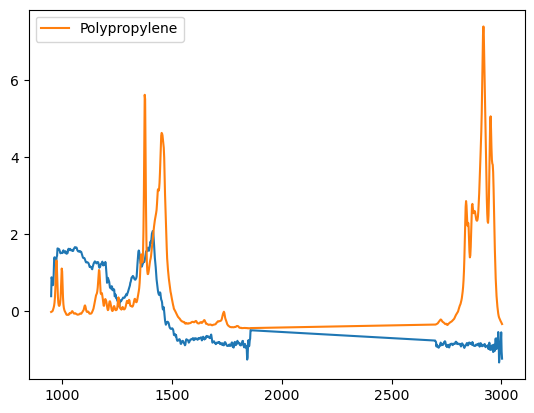

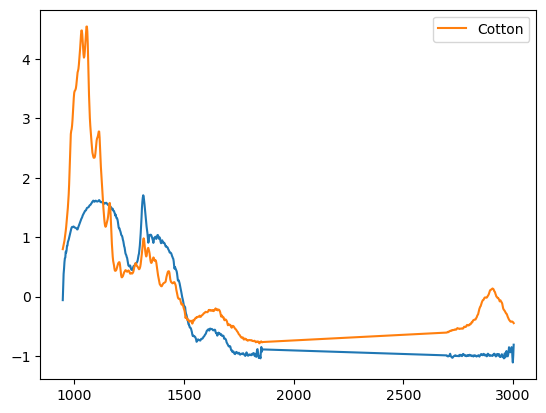

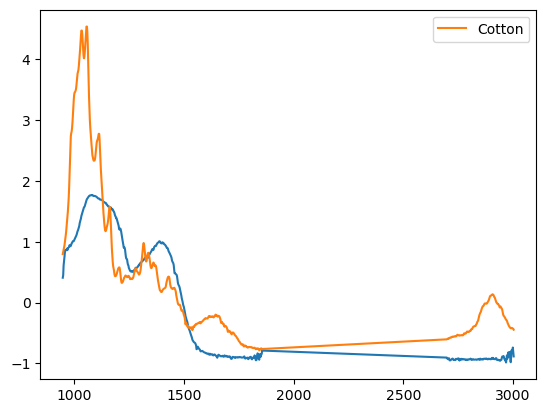

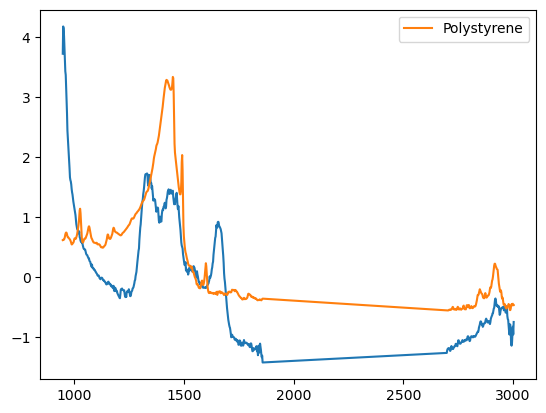

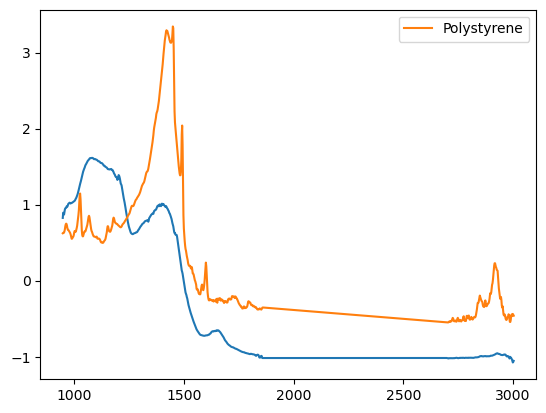

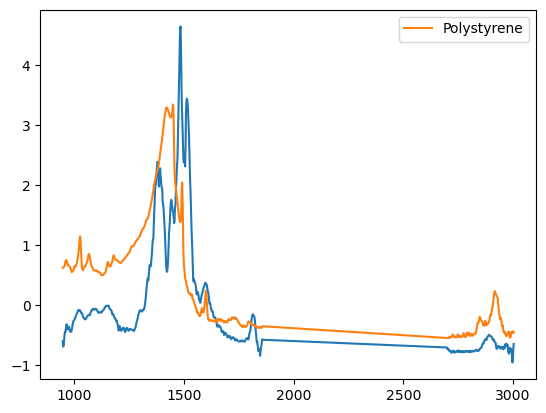

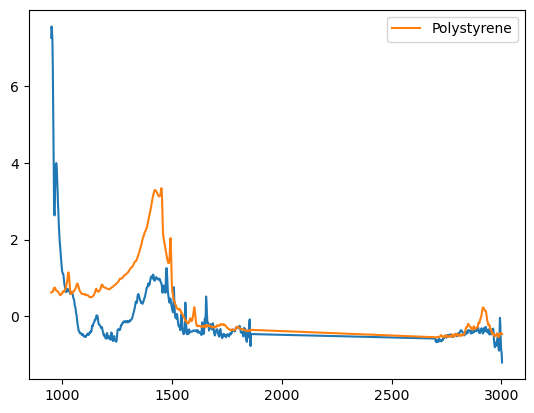

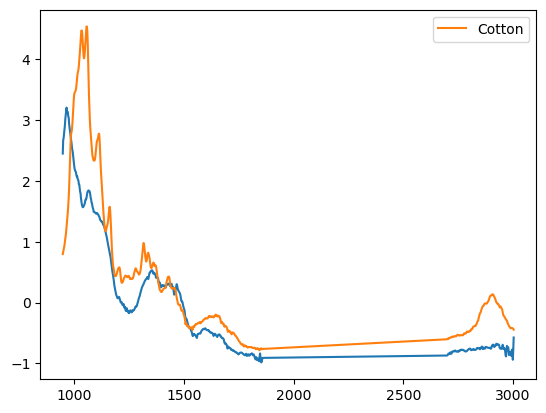

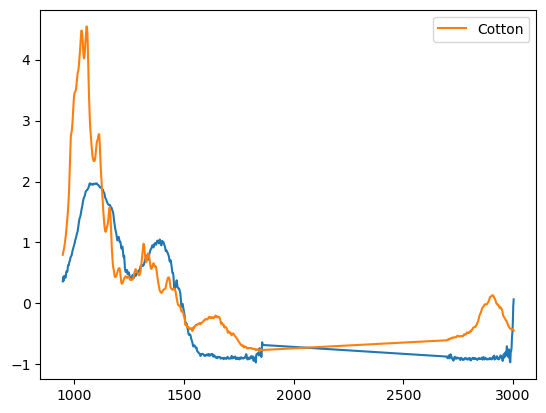

In [224]:
for i in range(80):
    if pred_probs_2[i] < 0.7:
        continue
    x = "particle"+str(i)
    polymer = pred_polymers_2[i]
    plt.plot(
        spectra_2_df_long_int.query('file_name == "particle0"').loc[idx_range,'wavelength'].reset_index(drop=True),
        spectra_2_df_long_int.query('file_name == @x').loc[idx_range,'intensity'].reset_index(drop=True)
    )
    
    plt.plot(-df_flopp_pivot.query('polymer==@polymer').iloc[0,3:][idx_range], label=polymer)
    plt.legend()
    plt.show()
    
#plt.plot(-df_flopp_pivot.query('polymer=="Rubber"').iloc[0,3:][idx_range])

In [245]:
pred_polymers_hqi = corr_matching(-x_train, y_train, spectra_df_long_int_pivot.iloc[:,1:].iloc[:,idx_range], r_min=0.7)[0].to_numpy()
pred_probs_hqi = np.round(corr_matching(-x_train, y_train, spectra_df_long_int_pivot.iloc[:,1:].iloc[:,idx_range], r_min=0.7)[1]*100)


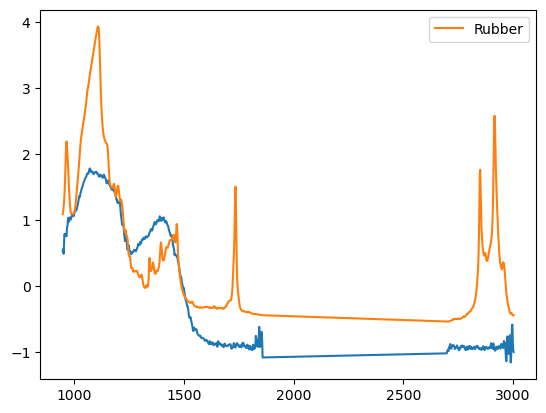

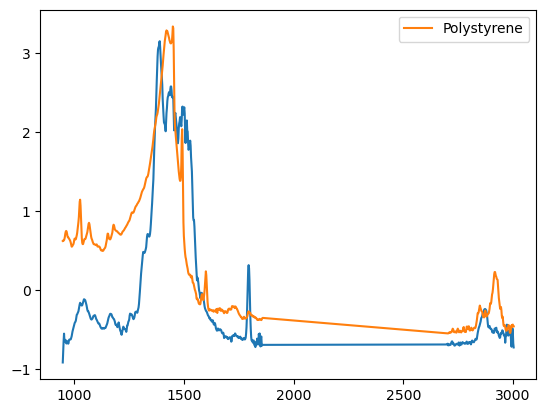

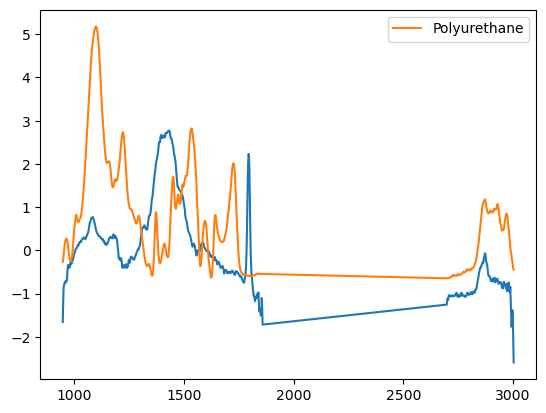

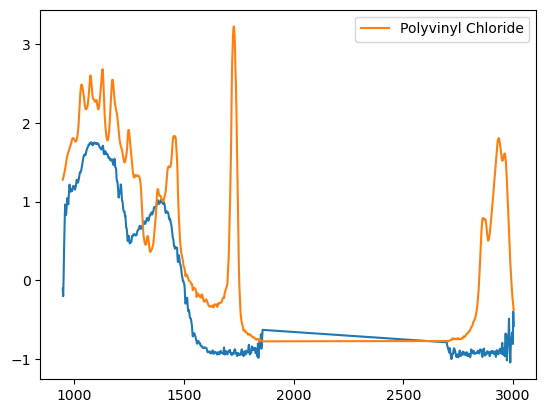

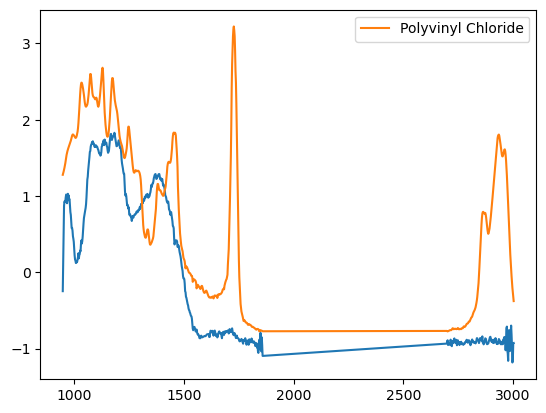

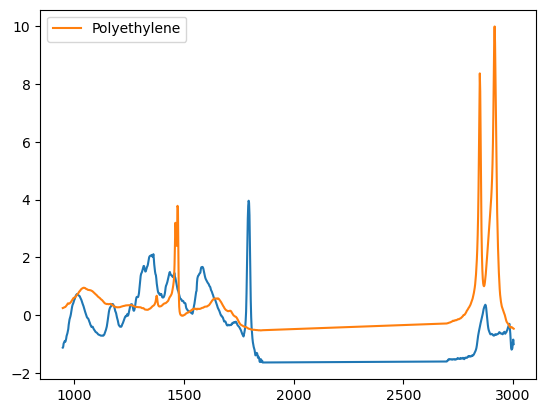

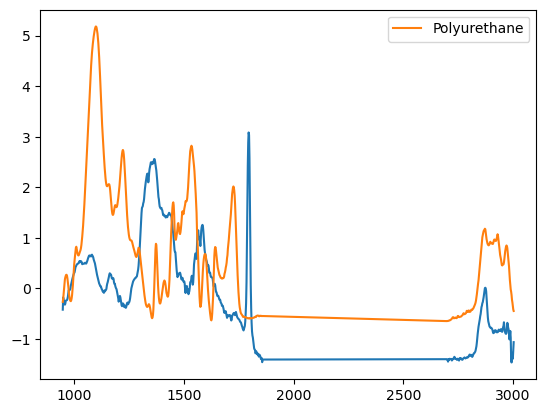

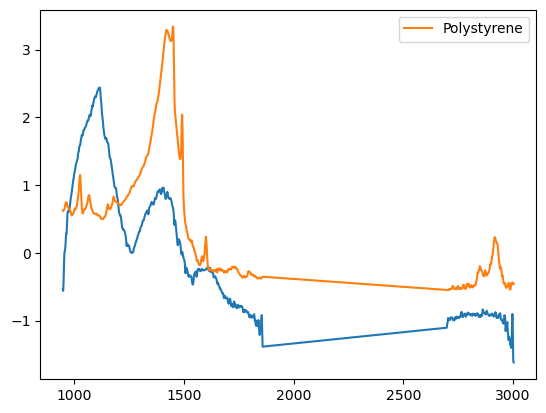

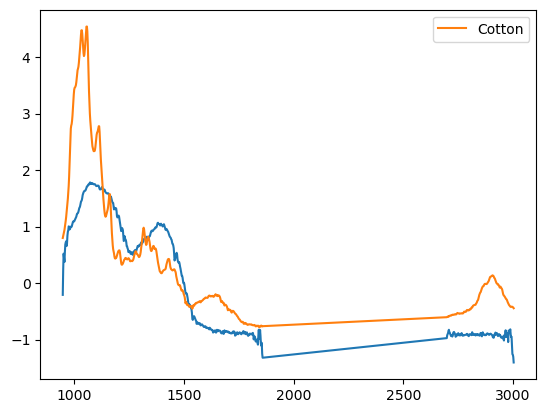

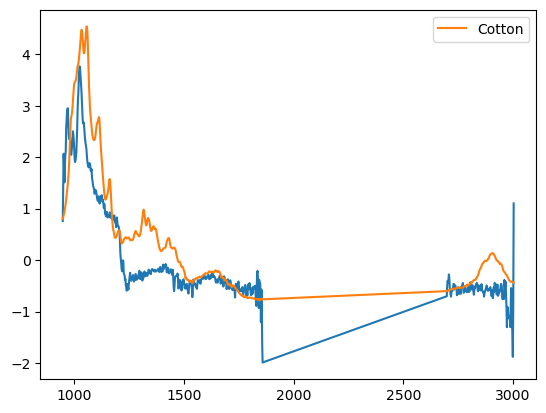

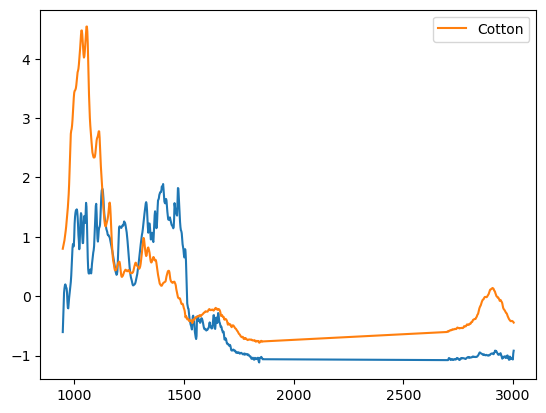

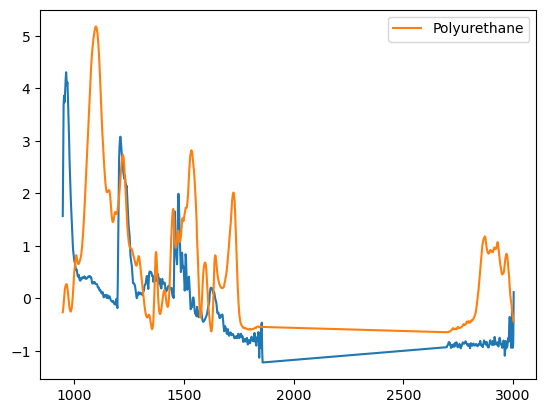

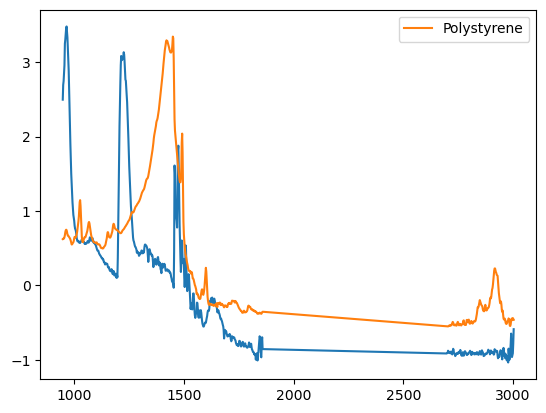

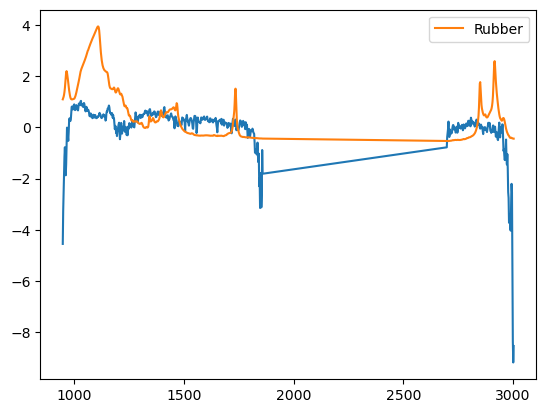

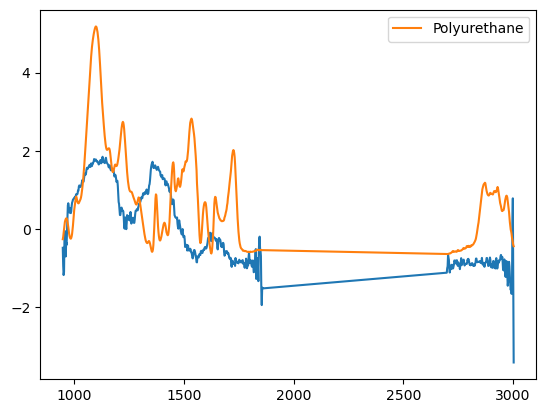

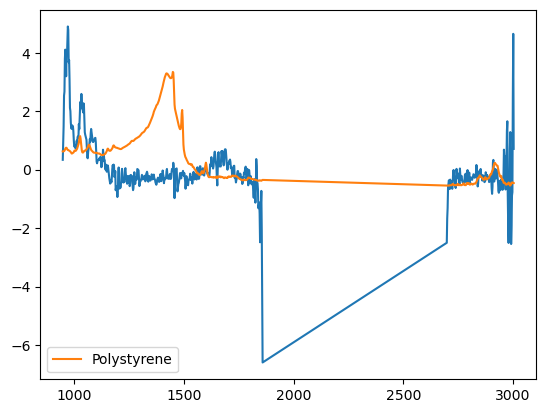

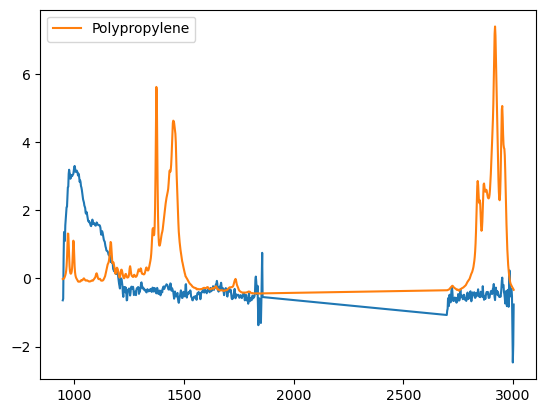

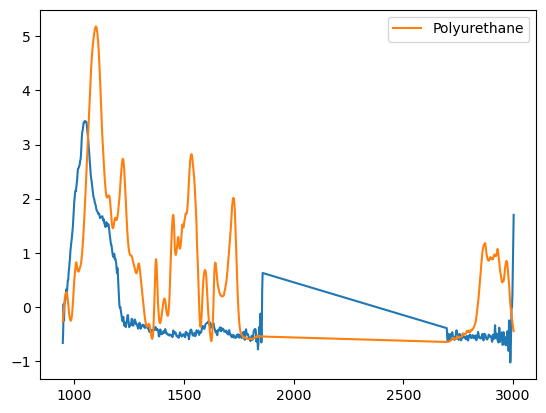

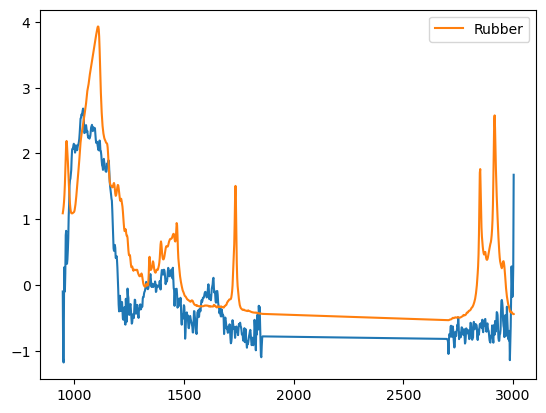

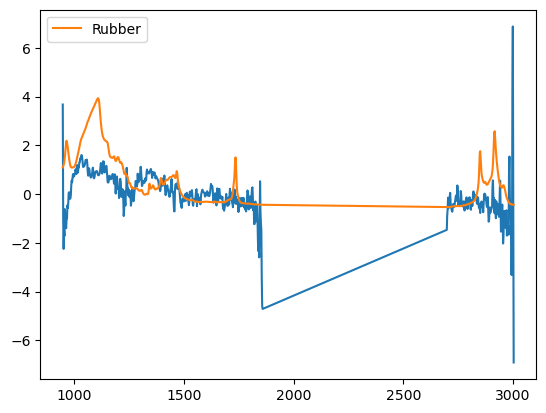

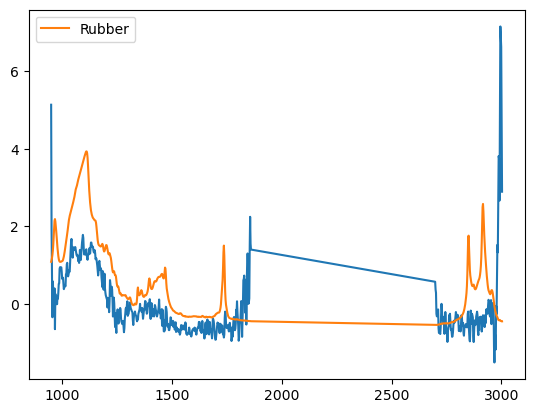

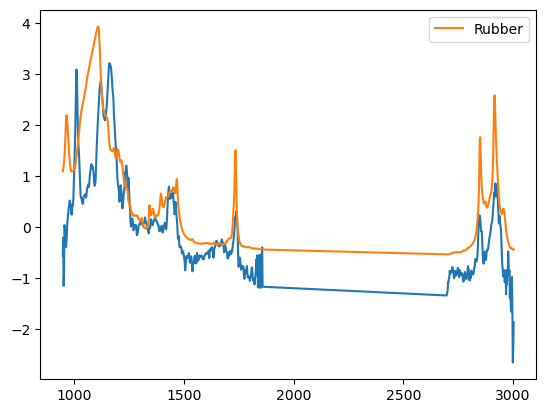

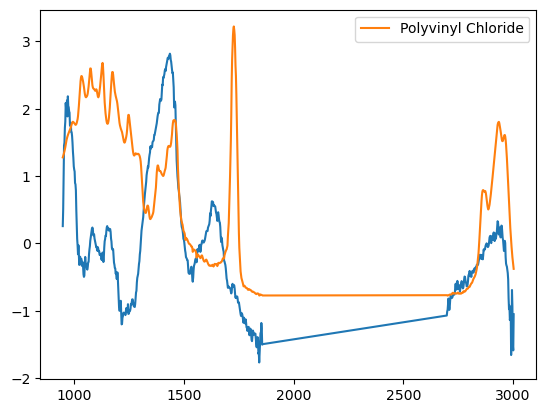

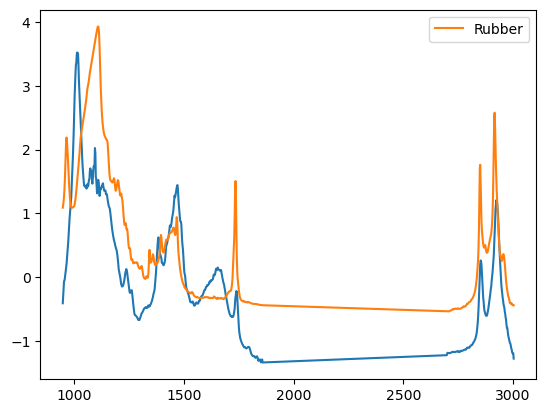

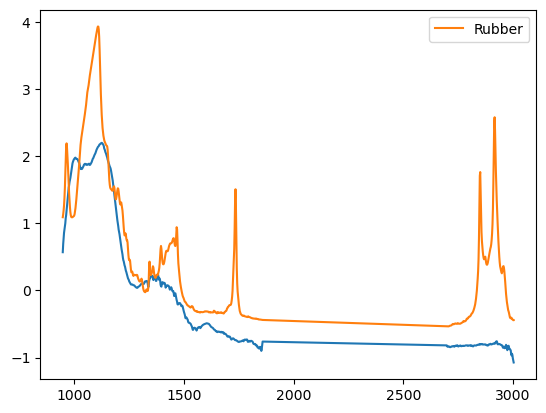

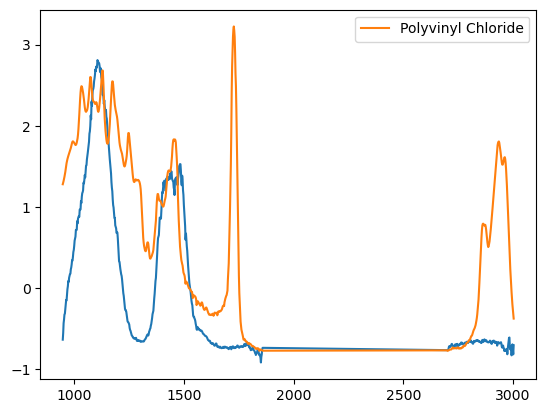

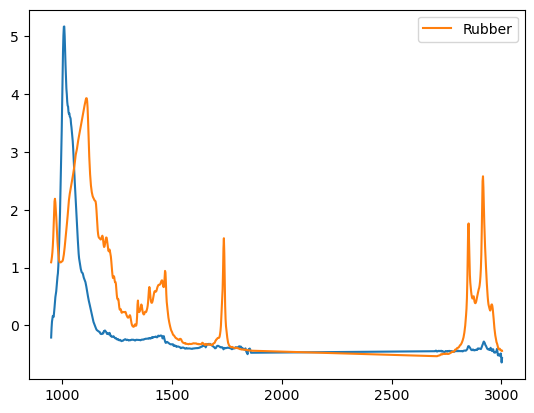

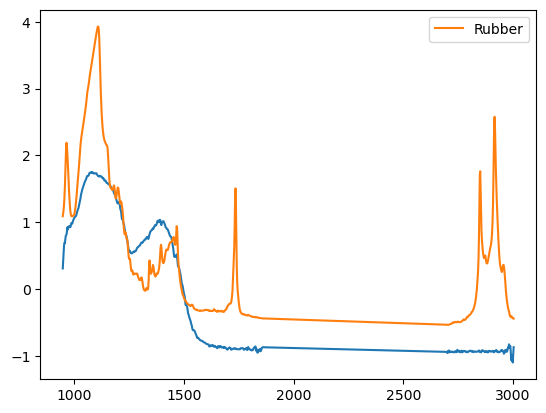

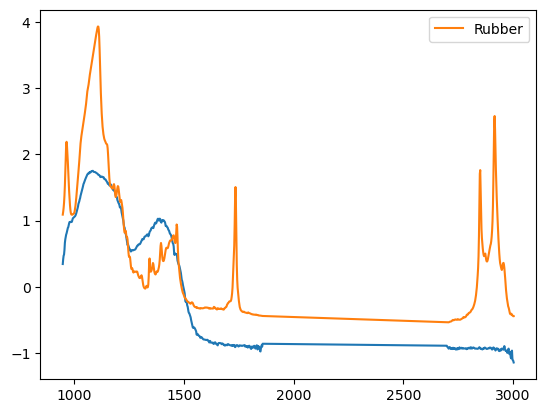

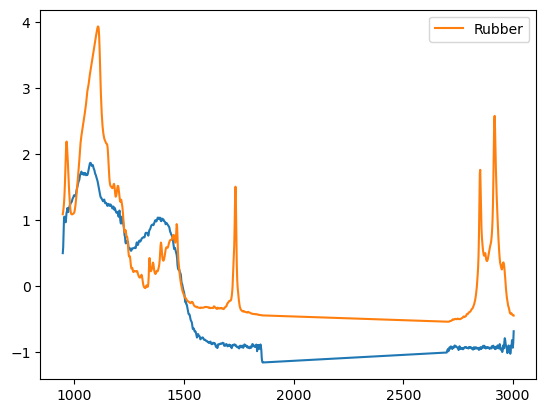

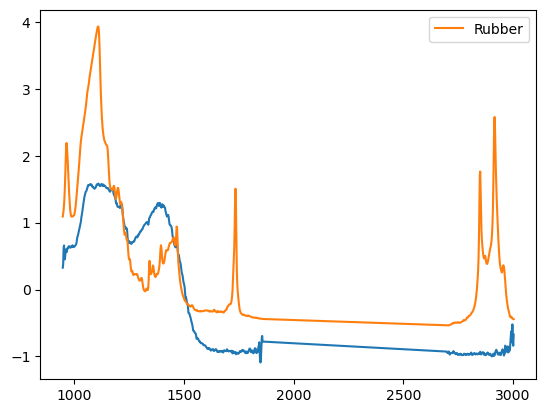

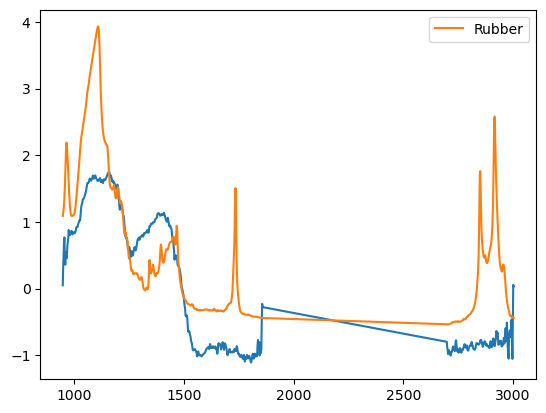

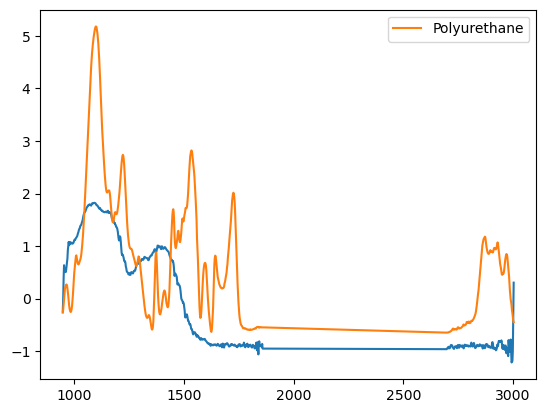

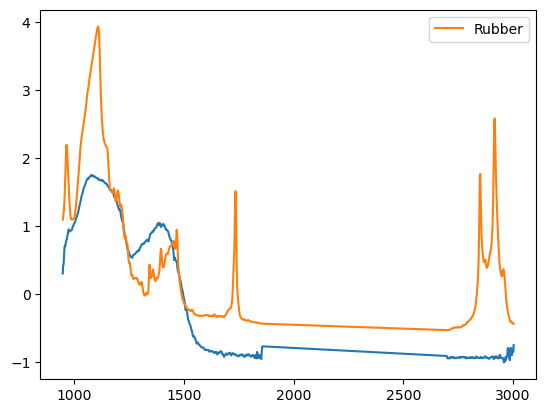

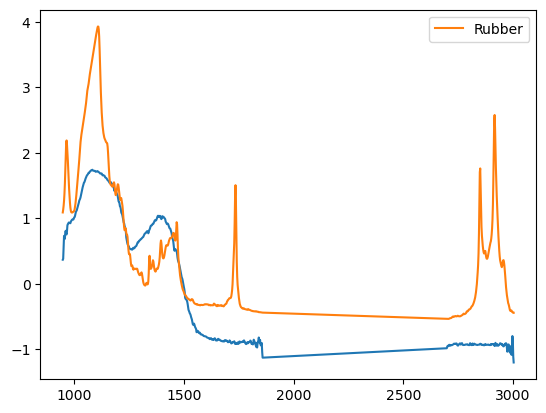

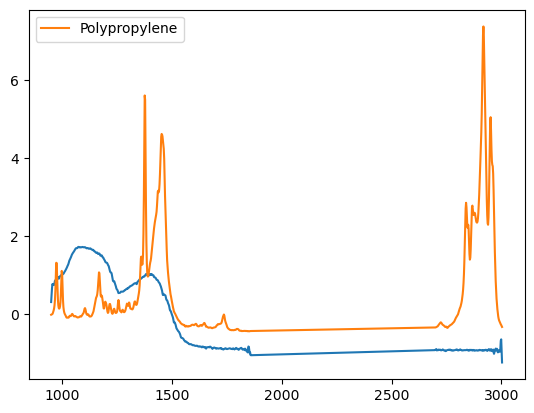

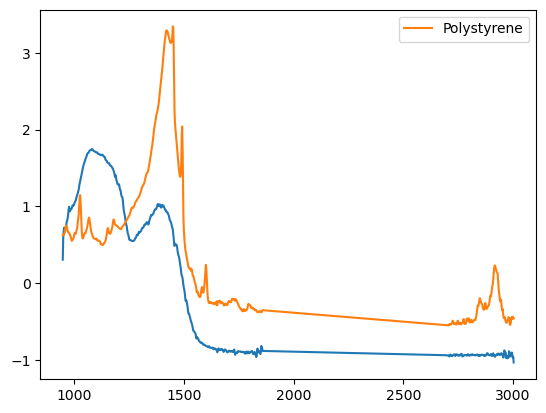

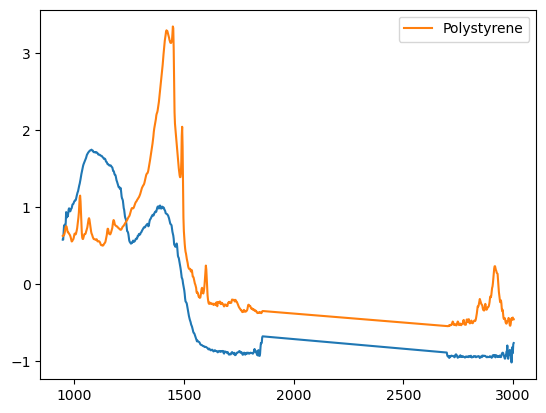

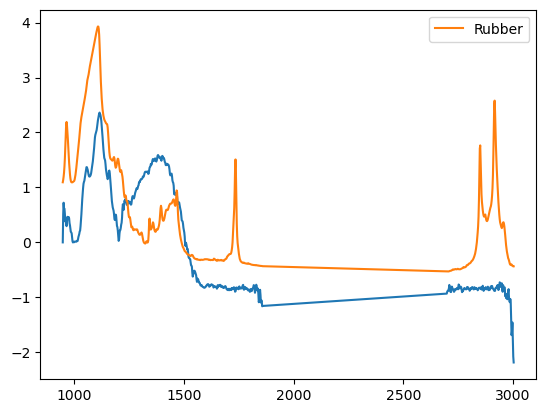

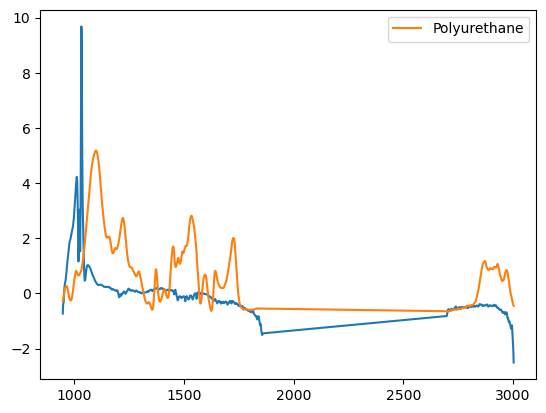

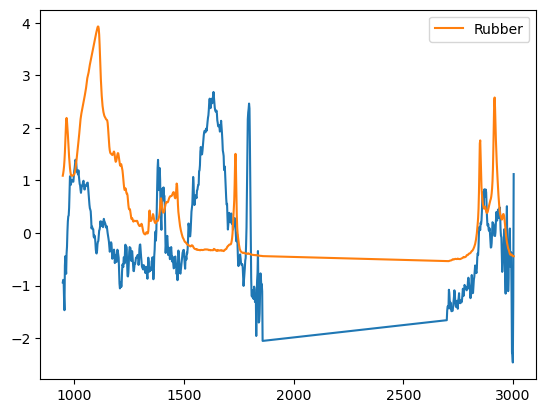

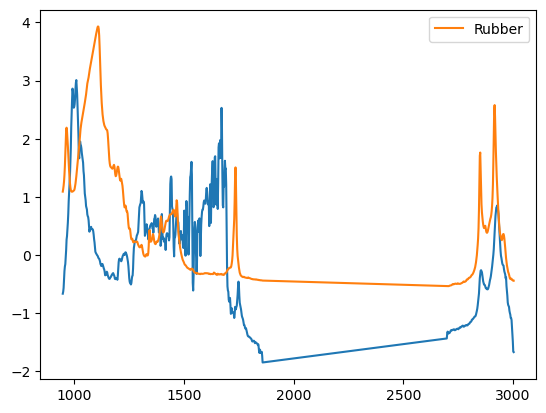

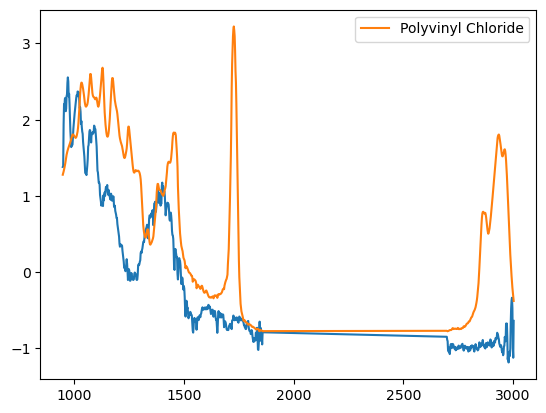

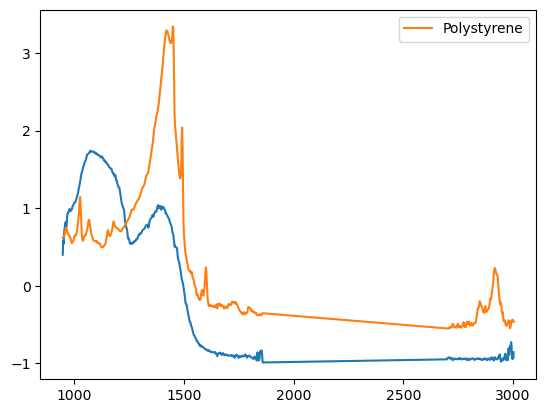

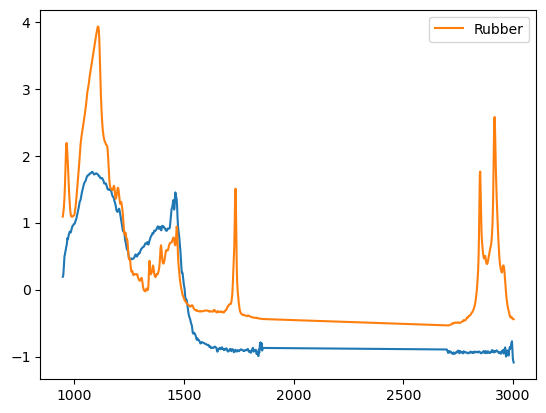

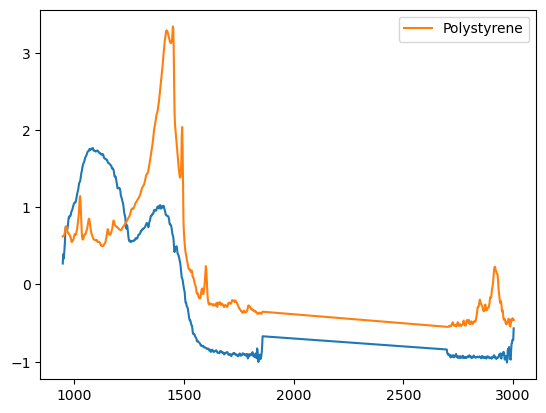

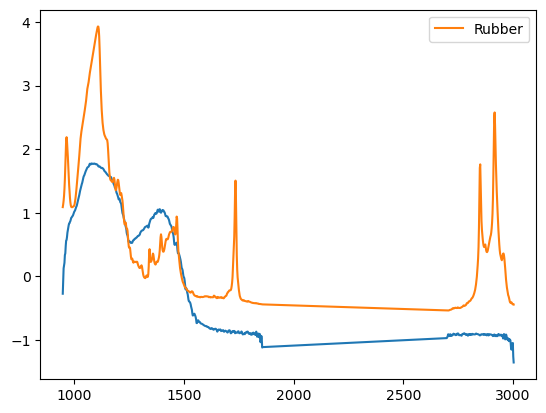

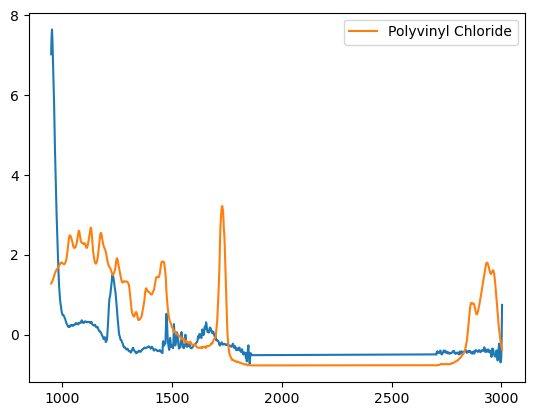

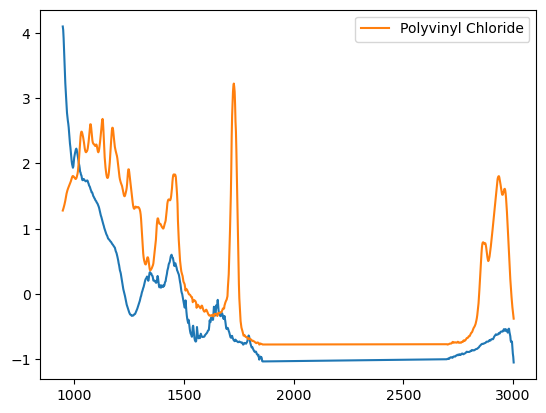

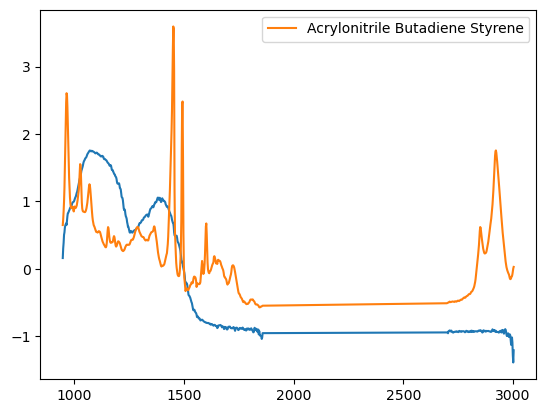

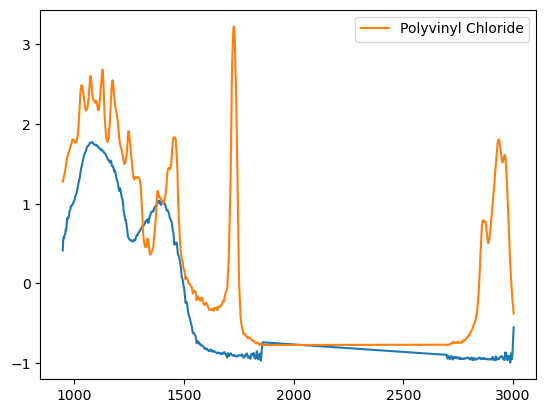

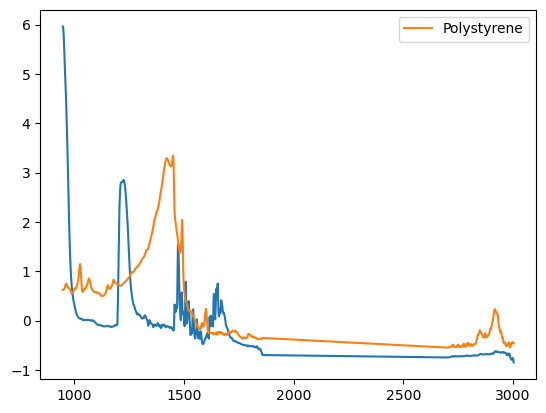

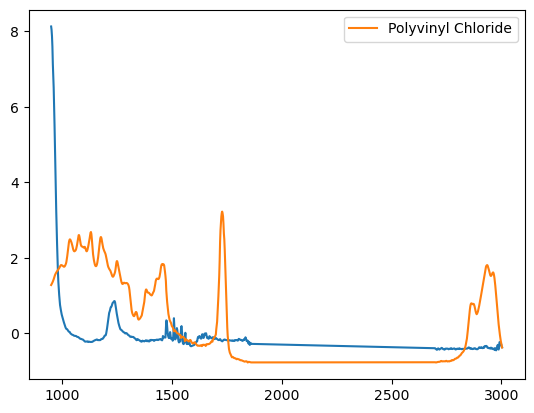

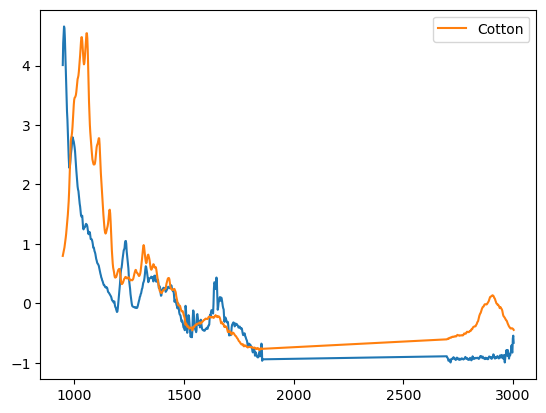

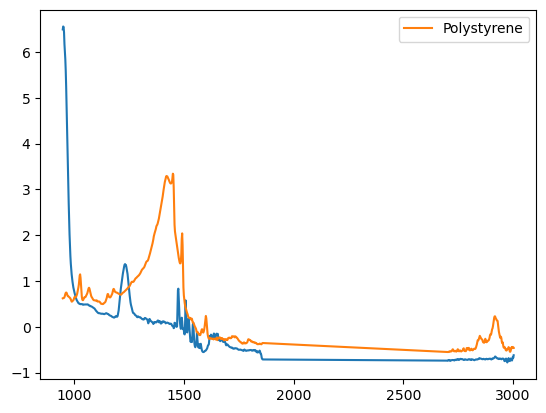

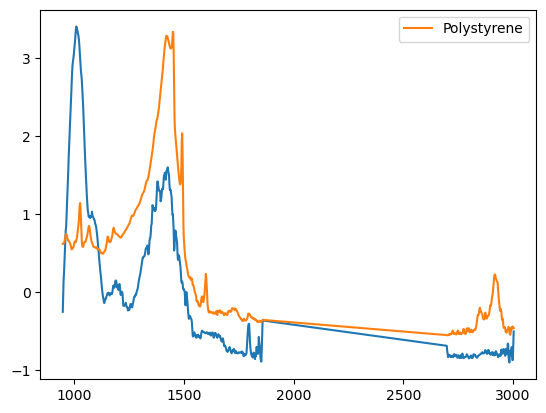

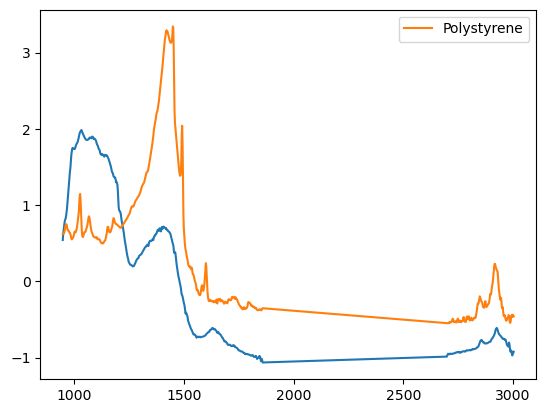

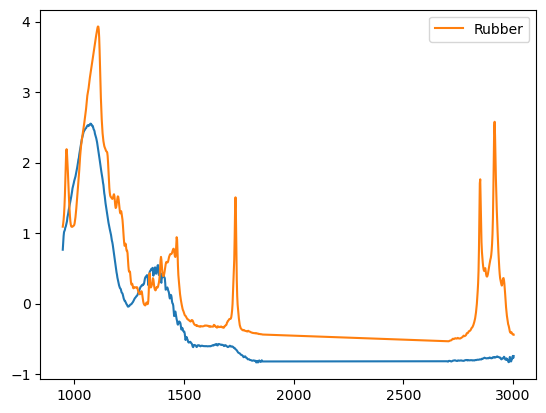

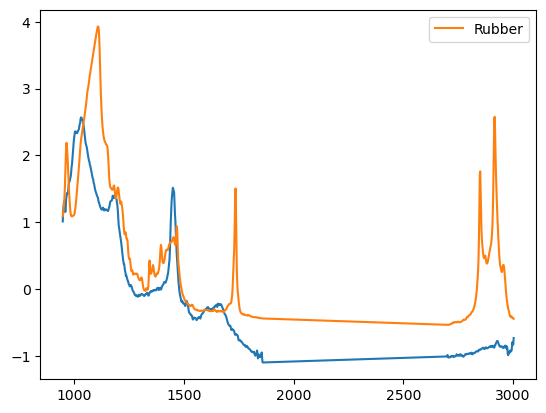

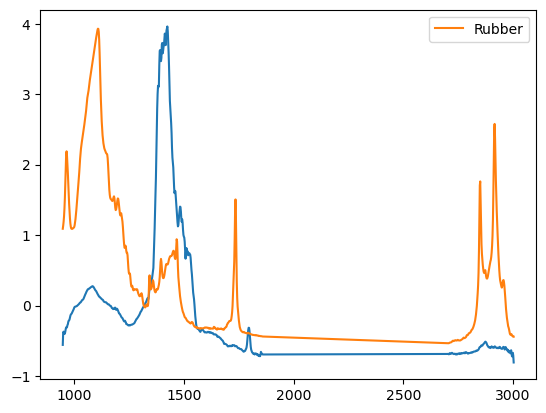

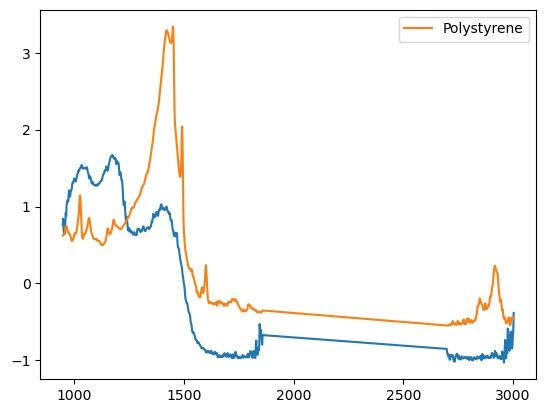

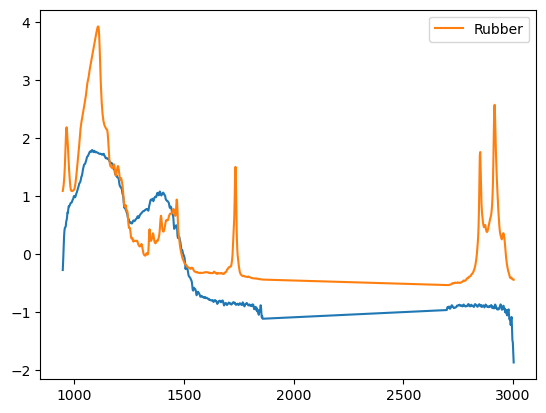

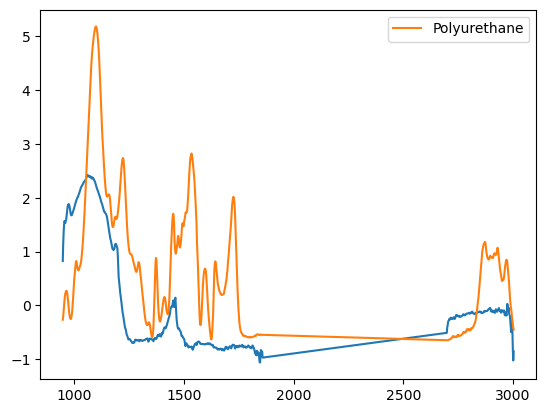

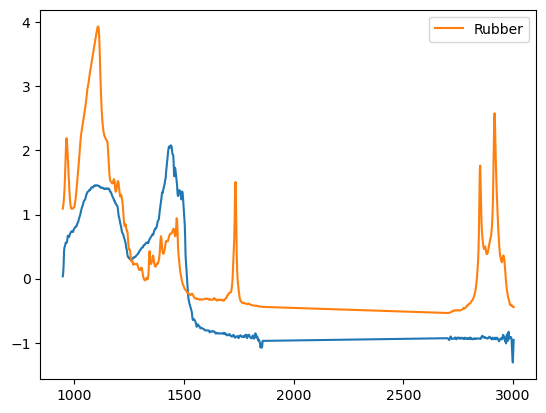

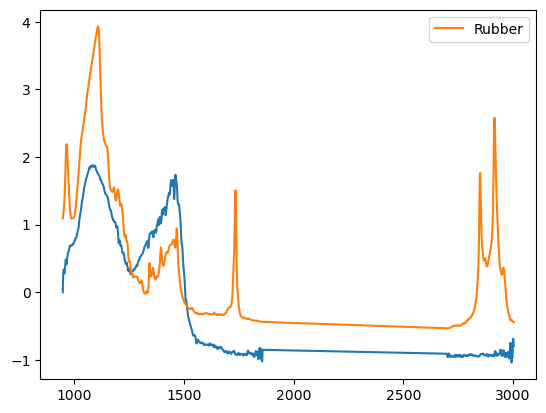

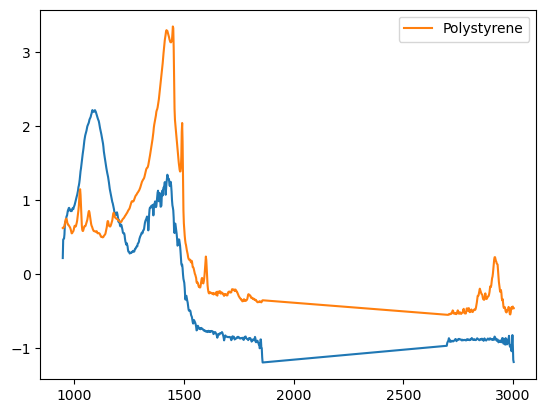

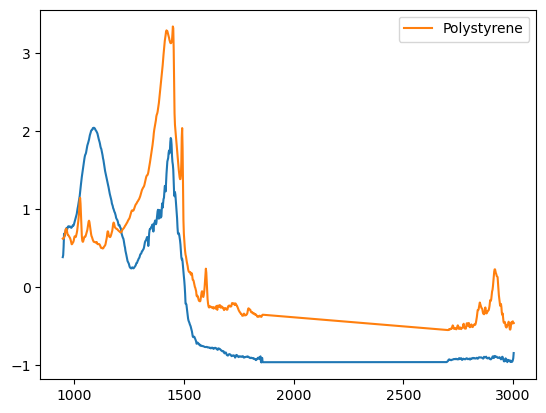

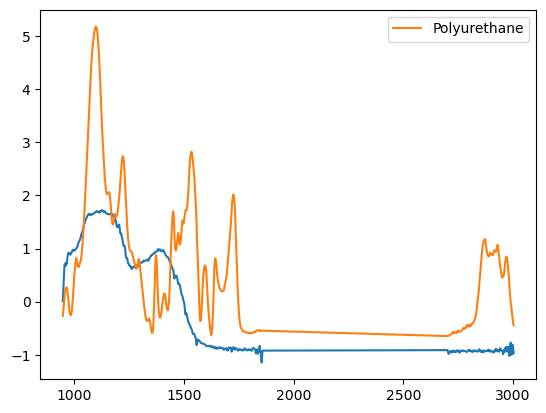

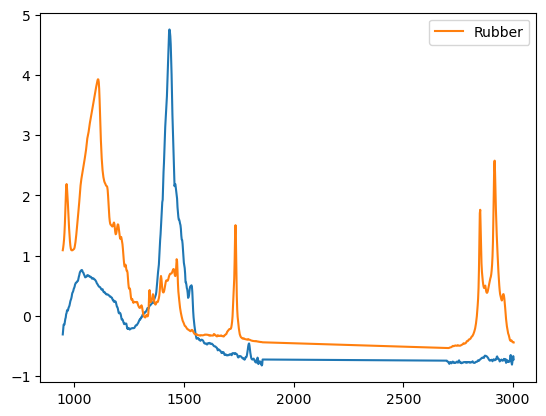

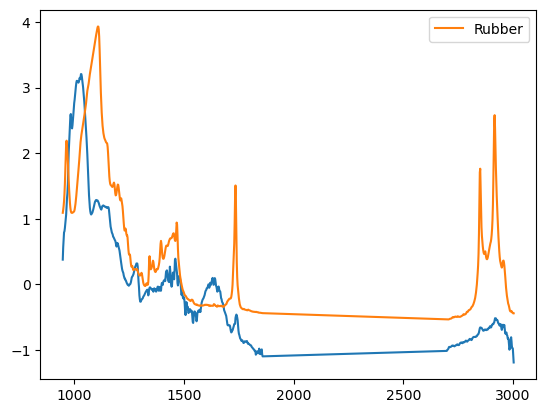

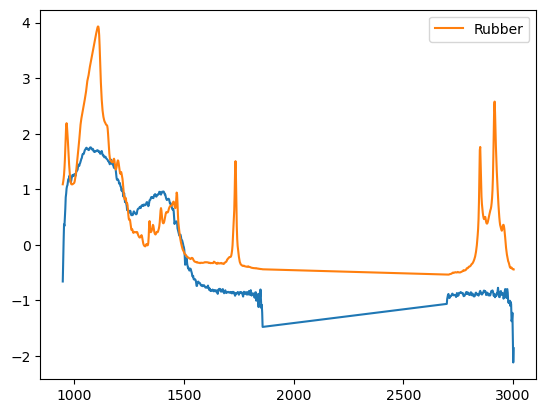

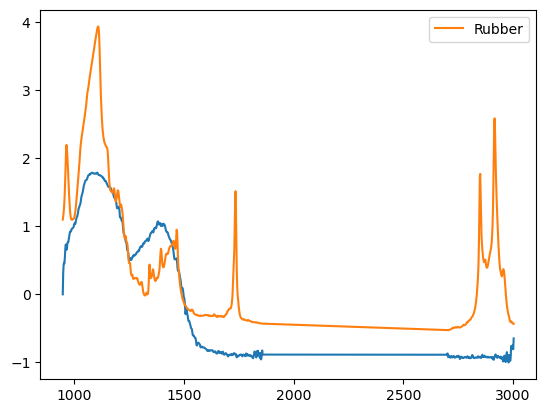

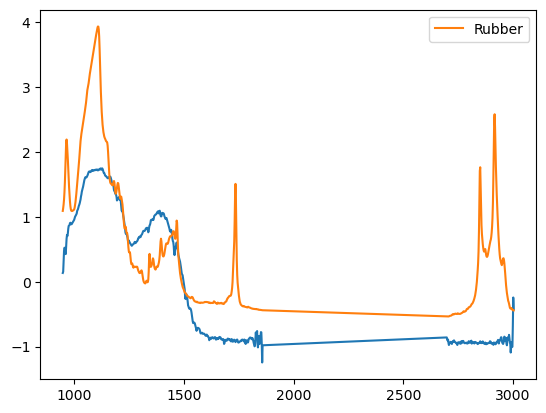

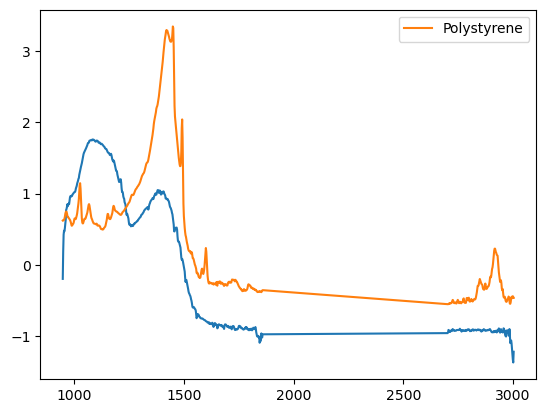

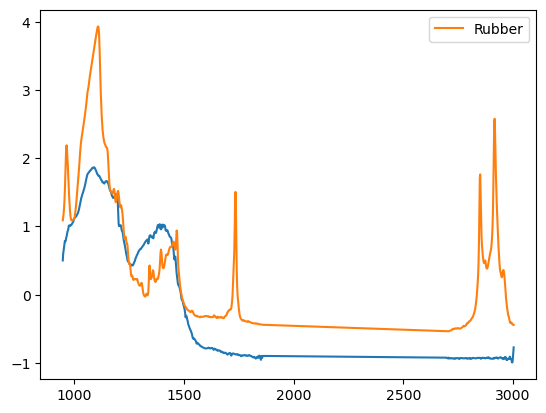

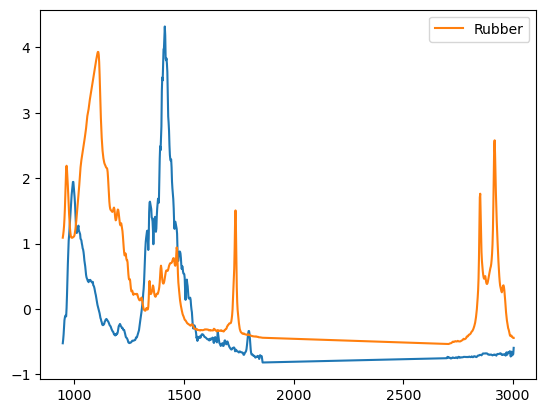

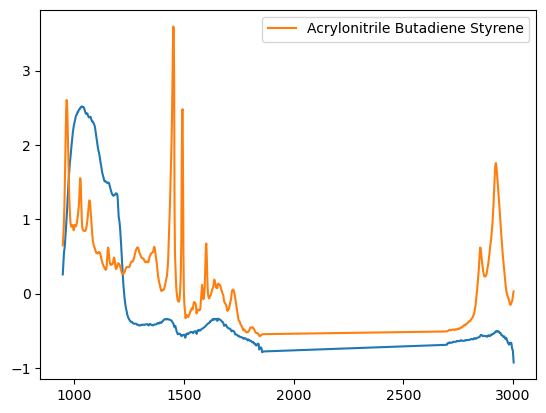

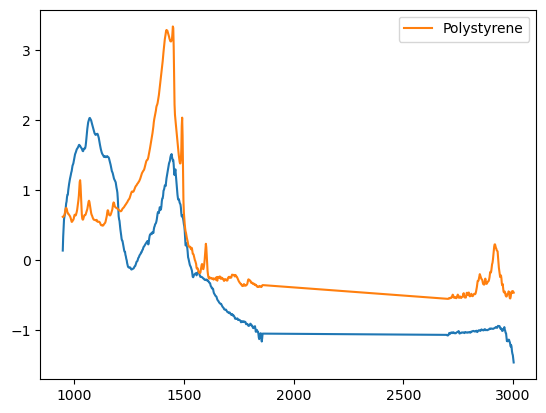

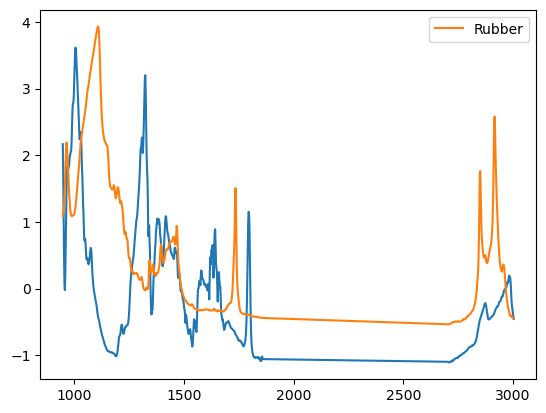

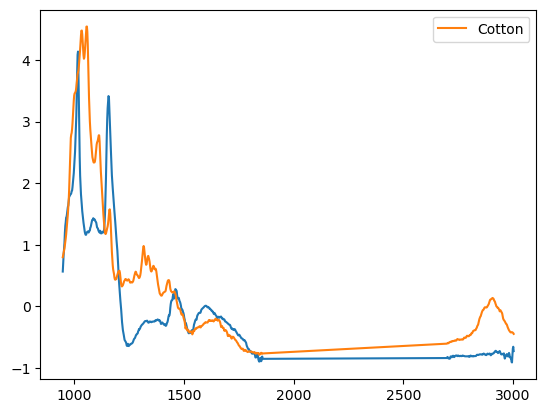

In [246]:
for i in range(80):
    if pred_probs_hqi[i] < 0.7:
        continue
    x = "particle"+str(i)
    polymer = pred_polymers_hqi[i]
    plt.plot(
        spectra_df_long_int.query('file_name == "particle0"').loc[idx_range,'wavelength'].reset_index(drop=True),
        spectra_df_long_int.query('file_name == @x').loc[idx_range,'intensity'].reset_index(drop=True)
    )
    
    plt.plot(-df_flopp_pivot.query('polymer==@polymer').iloc[0,3:][idx_range], label=polymer)
    plt.legend()
    plt.show()
    
#plt.plot(-df_flopp_pivot.query('polymer=="Rubber"').iloc[0,3:][idx_range])

In [247]:
pred_probs_hqi

array([89., 78., 86., 75., 83., 43., 85., 63., 93., 92., 92., 55., 87.,
       53., 79., 75., 89., 90., 95., 93., 89., 89., 90., 88., 86., 85.,
       88., 89., 89., 89., 89., 89., 83., 82., 84., 68., 79., 92., 89.,
       87., 88., 88., 59., 92., 89., 65., 89., 70., 53., 86., 74., 89.,
       91., 94., 93., 88., 74., 89., 88., 93., 88., 89., 90., 91., 88.,
       88., 95., 90., 89., 88., 88., 89., 89., 87., 93., 89., 70., 83.,
       89., 93.])

In [248]:


df_res = pd.DataFrame({'Logistic Reg Pred':pred_polymers_1,
'Logistic Reg Prob':np.round(pred_probs_1*100),
'HQI Pred':pred_polymers_hqi,
'HQI':pred_probs_hqi})
df_res


,Logistic Reg Pred,Logistic Reg Prob,HQI Pred,HQI
0,Cotton,41.0,Rubber,89.0
1,Polystyrene,100.0,Polystyrene,78.0
2,Polystyrene,96.0,Polyurethane,86.0
3,Acrylonitrile Butadiene Styrene,90.0,Polyvinyl Chloride,75.0
4,Acrylonitrile Butadiene Styrene,55.0,Polyvinyl Chloride,83.0
...,...,...,...,...
75,Polystyrene,97.0,Rubber,89.0
76,Polystyrene,85.0,Acrylonitrile Butadiene Styrene,70.0
77,Polystyrene,30.0,Polystyrene,83.0
78,Polystyrene,44.0,Rubber,89.0


In [249]:
(df_res.loc[:,'Logistic Reg Pred'] == df_res.loc[:,'HQI Pred']).sum()

20